# HydroWatch Amur — решение (Sentinel-1 + Sentinel-2)

КосмоХакатон 2026 · «Оперативный мониторинг гидрологической динамики»

Ноутбук прогоняет решение от паспортов сцен до `submission.csv`, масок, векторных
контуров, сводных отчётов и интерактивной карты.

## Что внутри

| Модуль | Метод |
|---|---|
| Сегментация SAR | потайловый порог: формальные тесты бимодальности (BC ≥ 0.555, Ashman D ≥ 3) + Otsu/Kittler–Illingworth, медиана по принятым тайлам |
| Защита от ложной воды | вето по яркости тёмной моды (асфальт/ВПП) + физически жёсткий откат |
| Сегментация оптики | адаптивный (Otsu) порог MNDWI + AWEIsh для мутной паводковой воды |
| Слияние каналов | консенсус SAR∧оптика там, где оптика видит землю; SAR один — где нет (как строился эталон). Альтернативы (Демпстер–Шейфер, OR) — в калибровке |
| Детекция изменений | требование падения σ⁰ ≥ 3 дБ между датами |
| Постобработка | HAND/уклон/застройка, минимальная картируемая единица, связность с руслом |
| Калибровка | перебор конфигураций с валидацией **по районам** (leave-one-AOI-out) |
| Выходы | `submission.csv`, маски GeoTIFF, GeoJSON-контуры, JSON-отчёты, карта |

## Как пользоваться

1. Разделы 1–6 — установка, данные, авторизация, код (выполнить один раз).
2. Раздел 8 — прогон одной пары для быстрой проверки.
3. Раздел 10 — полный прогон **с чекпоинтами на Google Drive**: при обрыве сессии
   Colab просто запустите ячейку заново, уже посчитанные пары подхватятся.
4. Раздел 12 — **калибровка**: перебирает конфигурации на закэшированных снимках и
   выбирает лучшую честно, по отложенным районам. Именно она доводит Score.
5. Разделы 11, 13–15 — самопроверка по метрике, карта, отчёты, сборка сдачи.

**Ориентировочное время полного прогона:** 15–25 минут на холодную (упирается в сеть —
сотни запросов к Earth Engine), ~1 минута при возобновлении из чекпоинтов.


## 1. Установка зависимостей

In [1]:
%pip install -q earthengine-api rasterio pyproj scipy pandas numpy matplotlib tqdm folium pyyaml kagglehub

## 2. Датасет `hydrowatch_amur/`

Датасет опубликован на Kaggle:
[`shotme/cosmohack-blagoveshensk`](https://www.kaggle.com/datasets/shotme/cosmohack-blagoveshensk).
Google Drive / zip оставлены как запасной вариант.

Даже у публичного датасета Kaggle API требует привязанный аккаунт. Настройте одно из двух:
**Colab Secrets** (иконка ключа слева → `KAGGLE_USERNAME` и `KAGGLE_KEY` со страницы
`kaggle.com/settings` → "Create New Token") либо дождитесь интерактивного
`kagglehub.login()` из ячейки ниже.

Ячейка переживает лишнюю вложенность папок, которую создаёт веб-загрузчик Kaggle
(`rasters/rasters/...`) — см. `hydrowatch/paths.py`.


In [2]:
import os

KAGGLE_DATASET = "shotme/cosmohack-blagoveshensk"
DATA_DIR = None

# --- Вариант A: Kaggle (основной) ---
if os.path.isdir("/kaggle/input"):
    # Уже внутри Kaggle Notebook — датасет примонтирован платформой
    for root, dirs, files in os.walk("/kaggle/input"):
        if "pairs.csv" in files:
            DATA_DIR = root
            break

if DATA_DIR is None:
    import kagglehub

    try:
        from google.colab import userdata
        for key in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
            try:
                os.environ[key] = userdata.get(key)
            except Exception:
                pass
    except ImportError:
        pass

    try:
        kaggle_root = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception as e:
        print("Не получилось скачать по секретам:", e, "\nОткрываю интерактивный вход...")
        kagglehub.login()
        kaggle_root = kagglehub.dataset_download(KAGGLE_DATASET)
    print("Kaggle dataset downloaded to:", kaggle_root)
    for root, dirs, files in os.walk(kaggle_root):
        if "pairs.csv" in files:
            DATA_DIR = root
            break

# --- Вариант B: Google Drive (запасной) ---
if DATA_DIR is None or not os.path.isdir(DATA_DIR):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass
    DATA_DIR = "/content/drive/MyDrive/cosmohack2/hydrowatch_amur"

# --- Вариант C: zip, загруженный вручную (запасной) ---
if not os.path.isdir(DATA_DIR):
    ZIP_PATH = "/content/hydrowatch_amur.zip"
    if os.path.exists(ZIP_PATH):
        import zipfile
        with zipfile.ZipFile(ZIP_PATH) as zf:
            zf.extractall("/content/")
        DATA_DIR = "/content/hydrowatch_amur"

assert os.path.isdir(DATA_DIR), f"DATA_DIR не найден: {DATA_DIR}"
print("DATA_DIR =", DATA_DIR)


Using Colab cache for faster access to the 'cosmohack-blagoveshensk' dataset.
Kaggle dataset downloaded to: /kaggle/input/cosmohack-blagoveshensk
DATA_DIR = /kaggle/input/cosmohack-blagoveshensk


## 3. Google Drive: чекпоинты и результаты

Полный прогон упирается в сеть (сотни запросов к Earth Engine), а сессии Colab обрываются.
Поэтому после каждой посчитанной пары в `CHECKPOINT_DIR` на Drive кладутся маски
(сжатые uint8 GeoTIFF — считанные сотни килобайт) и `summary.json`. При повторном запуске
готовые пары подхватываются, а не пересчитываются.

`summary.json` пишется **последним** — его наличие и есть признак «пара досчитана»,
поэтому пара, прерванная на середине записи, будет пересчитана, а не подхвачена битой.

### Что и куда скачивается из интернета

| Источник | Что | Объём |
|---|---|---|
| Kaggle (`shotme/cosmohack-blagoveshensk`) | 104 файла датасета: 58 JSON-паспортов, 22 GeoTIFF (эталоны + AUX), 15 CSV, 4 GeoJSON | ~0.4 ГБ |
| Google Earth Engine | **444 запроса окон** (164 SAR + 280 оптика) → сшиваются в 22 файла-кэша, по 2 на пару | ~1.5-2.5 ГБ |

Всё, что скачивается, при `CACHE_ARRAYS = True` оседает на вашем Google Drive в
`MyDrive/cosmohack2/hydrowatch_run/checkpoints/<pair_id>/` — оттуда это можно
забрать в репозиторий. Результаты решения — в `.../hydrowatch_run/outputs/`.

**Для git:** кэш снимков (`arrays_*.npz`) в репозиторий класть не стоит — это гигабайты
производных данных, которые воспроизводятся одним прогоном. В репозиторий имеет смысл
коммитить `outputs/` (submission.csv, маски, контуры, отчёты) — они на порядки меньше.


In [3]:
import os

DRIVE_ROOT = "/content/drive/MyDrive"
try:
    from google.colab import drive
    if not os.path.isdir(DRIVE_ROOT):
        drive.mount('/content/drive')
except ImportError:
    pass  # не в Colab — пишем локально

if os.path.isdir(DRIVE_ROOT):
    WORK_DIR = os.path.join(DRIVE_ROOT, "cosmohack2", "hydrowatch_run")
else:
    WORK_DIR = "/content/hydrowatch_run" if os.path.isdir("/content") else "./hydrowatch_run"

CHECKPOINT_DIR = os.path.join(WORK_DIR, "checkpoints")
OUT_DIR = os.path.join(WORK_DIR, "outputs")
for d in (CHECKPOINT_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

RESUME = True        # False = пересчитать всё с нуля
CACHE_ARRAYS = True  # сохранять сами скачанные снимки на Drive (см. ниже)

print("WORK_DIR      =", WORK_DIR)
print("CHECKPOINT_DIR=", CHECKPOINT_DIR, " <- сюда кладутся маски и кэш снимков")
print("OUT_DIR       =", OUT_DIR, " <- сюда кладутся submission.csv, отчёты, контуры, карта")
print("RESUME        =", RESUME)
print("CACHE_ARRAYS  =", CACHE_ARRAYS)
if CACHE_ARRAYS:
    print()
    print("Кэш снимков займёт ~1.5-2.5 ГБ на Drive (float16, сжатый npz).")
    print("Он нужен раздела 12 (калибровка): десятки конфигураций пересегментируются")
    print("без единого обращения к Earth Engine. Выключите, если место на Drive дорого.")


Mounted at /content/drive
WORK_DIR      = /content/drive/MyDrive/cosmohack2/hydrowatch_run
CHECKPOINT_DIR= /content/drive/MyDrive/cosmohack2/hydrowatch_run/checkpoints  <- сюда кладутся маски и кэш снимков
OUT_DIR       = /content/drive/MyDrive/cosmohack2/hydrowatch_run/outputs  <- сюда кладутся submission.csv, отчёты, контуры, карта
RESUME        = True
CACHE_ARRAYS  = True

Кэш снимков займёт ~1.5-2.5 ГБ на Drive (float16, сжатый npz).
Он нужен раздела 12 (калибровка): десятки конфигураций пересегментируются
без единого обращения к Earth Engine. Выключите, если место на Drive дорого.


## 4. Авторизация в Google Earth Engine

Нужен **зарегистрированный** Earth Engine cloud-проект. Если получите
`403 ... is not registered to use Earth Engine` — откройте
`https://console.cloud.google.com/earth-engine/configuration?project=<ваш-project-id>`
тем же Google-аккаунтом и включите доступ (для хакатона подходит бесплатный
**Unpaid usage → Academic & Research**).

Используем **high-volume эндпоинт** — Google рекомендует именно его для большого числа
мелких параллельных запросов `computePixels`, а растр тянется окнами.


In [4]:
import ee

GEE_PROJECT = "cosmohack-bl"  # <-- ваш Earth Engine project id

HIGH_VOLUME = "https://earthengine-highvolume.googleapis.com"
try:
    ee.Initialize(project=GEE_PROJECT, opt_url=HIGH_VOLUME)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT, opt_url=HIGH_VOLUME)

print("Earth Engine OK")


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine OK


## 5. Пакет `hydrowatch`

Ячейки ниже разворачивают модули пакета через `%%writefile`. Содержимое идентично
`solution/src/hydrowatch/*.py` в репозитории решения — те же файлы, покрытые офлайн-тестами
(`solution/tests/test_pipeline.py`, 53 теста без сети), просто вставленные сюда, чтобы
ноутбук был самодостаточным.


In [5]:
import os
os.makedirs("/content/src/hydrowatch", exist_ok=True)
os.makedirs("/content/configs", exist_ok=True)
%cd /content

/content


In [6]:
%%writefile src/hydrowatch/__init__.py
"""HydroWatch Amur — baseline flood-mapping pipeline (SAR+optical fusion)."""

__version__ = "0.1.0"


Writing src/hydrowatch/__init__.py


In [7]:
%%writefile src/hydrowatch/config.py
"""Single source of truth for every threshold in the pipeline.

The rubric explicitly penalises thresholds hardcoded at their point of use
(«Пороги обратного рассеяния и спектральных индексов не зашиты числами по
месту»), and calibration (scripts/calibrate.py) needs to sweep them without
editing code. Every number below is therefore named, documented with its
provenance, and overridable from a YAML file.
"""
from __future__ import annotations

import json
from dataclasses import asdict, dataclass, field, fields


@dataclass
class SarConfig:
    # Physically plausible open-water sigma0 range. The case brief states the
    # reference labelling clamped Otsu to exactly this window. NOTE: this is
    # a clamp on the resulting *threshold*, never a filter on the pixels the
    # histogram is fitted to — fitting inside it removes the land mode and
    # biases the split (measured: IoU 0.59 vs 1.00 on a 10%-water scene).
    valid_range_db: tuple[float, float] = (-22.0, -12.0)
    speckle_filter_size: int = 5
    # "split" = per-tile Otsu + median (Chini et al. 2017 / Martinis et al.
    # 2009 family); "global" = one fit over the whole scene;
    # "global_in_range" = the biased v0 behaviour, kept for ablations.
    threshold_method: str = "split"
    # Tile side (px). Small enough that incidence-angle drift across the
    # swath is negligible inside one tile, large enough for a stable
    # histogram (the organizers' teaching notebook uses a 6x6 grid, i.e.
    # ~500-750 px tiles, on the same AOIs).
    tile_px: int = 512
    # --- Bimodality criteria (Cao et al., Water 11(4):786, 2019) ---
    # A tile only votes if BOTH formal tests pass. Otsu's own eta
    # (between-class / total variance) is deliberately NOT used as the gate:
    # on pure land it reads ~0.64 while returning a nonsense -8 dB
    # threshold, which is exactly how a scene with no water still produces
    # a confident, wrong answer.
    bimodality_coefficient_min: float = 0.555  # (skew^2 + 1) / kurtosis, > 5/9
    ashman_d_min: float = 3.0  # sqrt(2)|mu1-mu2| / sqrt(s1^2+s2^2)
    # Degenerate splits (a tile that is ~all water or ~all land) carry no
    # information about where the boundary sits.
    tile_water_fraction_range: tuple[float, float] = (0.05, 0.95)
    # Physical veto: the dark mode of a usable tile must actually be as dark
    # as open water. Guards against a smooth dry surface (asphalt, runway —
    # the brief's «ложная вода») which can be genuinely bimodal against
    # rough land yet is not water.
    water_dark_mode_max_db: float = -16.0
    min_dark_pixels: int = 50
    # Never fit on fewer than this many qualifying tiles before relaxing.
    min_bimodal_tiles: int = 2
    # Fallback when no tile passes: use the N tiles with the widest mode
    # separation instead of declaring the scene waterless. Returning "no
    # water" here cost an entire AOI (poyarkovo: 0 ha against 8910 ha
    # reference) in the first scored run.
    relaxed_fallback_tiles: int = 3
    # Blend Otsu with Kittler-Illingworth per tile (0 = pure Otsu, 1 = pure KI).
    ki_weight: float = 0.5
    histogram_bins: int = 128


@dataclass
class OpticalConfig:
    # Fixed thresholds mirror the reference-labelling recipe in the brief.
    mndwi_thresh: float = 0.1
    ndwi_thresh: float = 0.15
    ndvi_thresh: float = 0.2
    aweish_thresh: float = 0.0
    # Re-fit the MNDWI cut per scene with Otsu instead of using the fixed value.
    adaptive_threshold: bool = True
    # AWEIsh is the turbid-flood-water safeguard: suspended sediment lifts NIR
    # and pushes NDWI negative exactly during a flood peak (case brief,
    # "Как оптический сенсор видит воду").
    use_aweish: bool = True


@dataclass
class FusionConfig:
    # "ds"        = Dempster-Shafer (graded evidence, ignorance modelled)
    # "consensus" = SAR AND optical where optical is valid, SAR alone where
    #               it is not. This is how the *reference* was built
    #               («приоритет консенсуса радиолокационной и оптической
    #               ветвей»), and the metric scores agreement with it.
    # "strict_consensus" = same, but cloud means "not confirmed" rather than
    #               "trust the radar" — matches the near-empty reference
    #               masks on the cloudy 2021 peak dates.
    # "or"        = plain union (the v0 baseline)
    method: str = "consensus"
    # Half-width (dB / index units) of the soft transition around a threshold.
    sar_soft_margin_db: float = 1.5
    optical_soft_margin: float = 0.1
    # Evidence discounting: how much of each source's mass is kept vs. moved
    # to "unknown". Lower = the source is trusted less.
    sar_reliability: float = 0.85
    optical_reliability: float = 0.75
    decision_threshold: float = 0.5


@dataclass
class ChangeConfig:
    # The reference pipeline required backscatter to drop by >= 3 dB at the
    # peak before calling a pixel newly flooded. Mirroring that requirement
    # is the single cheapest way to suppress false positives that survive
    # independent per-date thresholding.
    require_backscatter_drop: bool = True
    min_drop_db: float = 3.0


@dataclass
class PostprocessConfig:
    # JRC GSW occurrence >= this is "permanent water" per the brief.
    permanent_occurrence_pct: float = 80.0
    # The reference labelling used 5 deg; the metric scores agreement with
    # that labelling, not with nature.
    slope_max_deg: float = 5.0
    hand_max_m: float = 25.0
    builtup_thresh: float = 0.5
    # Minimum mapping unit, in pixels (25 px = 0.25 ha at 10 m).
    min_mapping_unit_px: int = 25
    hydrography_buffer_px: int = 3
    connectivity_filter: bool = True


@dataclass
class Config:
    sar: SarConfig = field(default_factory=SarConfig)
    optical: OpticalConfig = field(default_factory=OpticalConfig)
    fusion: FusionConfig = field(default_factory=FusionConfig)
    change: ChangeConfig = field(default_factory=ChangeConfig)
    postprocess: PostprocessConfig = field(default_factory=PostprocessConfig)
    seed: int = 42

    @classmethod
    def from_dict(cls, data: dict) -> "Config":
        sections = {f.name: f.type for f in fields(cls)}
        kwargs = {}
        for name, value in (data or {}).items():
            if name not in sections:
                raise KeyError(f"unknown config section {name!r}")
            if name == "seed":
                kwargs[name] = value
                continue
            section_cls = {
                "sar": SarConfig,
                "optical": OpticalConfig,
                "fusion": FusionConfig,
                "change": ChangeConfig,
                "postprocess": PostprocessConfig,
            }[name]
            known = {f.name for f in fields(section_cls)}
            unknown = set(value) - known
            if unknown:
                raise KeyError(f"unknown keys in [{name}]: {sorted(unknown)}")
            kwargs[name] = section_cls(**value)
        return cls(**kwargs)

    @classmethod
    def load(cls, path: str | None) -> "Config":
        """Loads YAML (preferred) or JSON. `None` returns defaults."""
        if not path:
            return cls()
        with open(path, "r", encoding="utf-8") as fh:
            text = fh.read()
        if path.endswith((".yaml", ".yml")):
            import yaml

            data = yaml.safe_load(text)
        else:
            data = json.loads(text)
        return cls.from_dict(data)

    def to_dict(self) -> dict:
        return asdict(self)

    def replace(self, **section_overrides) -> "Config":
        """Returns a copy with named leaf values overridden, e.g.
        `cfg.replace(postprocess={"hand_max_m": 15.0})` — used by the
        calibration sweep so it never mutates shared state."""
        data = self.to_dict()
        for section, overrides in section_overrides.items():
            data[section] = {**data[section], **overrides}
        return Config.from_dict(data)


Writing src/hydrowatch/config.py


In [8]:
%%writefile src/hydrowatch/paths.py
"""Path resolution tolerant of upload-pipeline quirks.

Kaggle's web uploader, when you drag in top-level folders individually
(rather than zipping the whole dataset root), nests each one under itself:
``rasters/rasters/<event>/<aoi>/...``, ``vectors/vectors/...``, while files
dropped straight into the root (``pairs.csv``) stay unnested. The proper
fix is re-uploading the dataset as a single zip of the `hydrowatch_amur`
root — that preserves the original structure exactly. This module exists
so the pipeline still works on an already-published, oddly-nested copy
without needing to rewrite it in place (`/kaggle/input/...` is read-only
anyway).
"""
from __future__ import annotations

import glob
import os


def resolve(data_dir: str, rel_path: str) -> str:
    """Returns a real path under `data_dir` matching `rel_path`, trying the
    direct join first and falling back to a recursive search so extra
    nesting levels (single, double, or otherwise) don't matter.

    Raises FileNotFoundError with both the direct and searched location if
    nothing matches, so a genuinely missing file still fails loudly instead
    of silently resolving to the wrong thing.
    """
    direct = os.path.join(data_dir, rel_path)
    if os.path.exists(direct):
        return direct

    pattern = os.path.join(data_dir, "**", rel_path)
    matches = glob.glob(pattern, recursive=True)
    if not matches:
        raise FileNotFoundError(
            f"{rel_path!r} not found under {data_dir!r} (checked {direct!r} "
            f"and recursively under {data_dir!r})"
        )
    return matches[0]


def try_resolve(data_dir: str, rel_path: str) -> str | None:
    try:
        return resolve(data_dir, rel_path)
    except FileNotFoundError:
        return None


Writing src/hydrowatch/paths.py


In [9]:
%%writefile src/hydrowatch/grid.py
"""Target-grid utilities.

The competition fixes the output grid per pair: 10 m, EPSG:32652, 3000-4500
px per side. The case brief is explicit that this grid is *defined by* the
reference masks ("Сетку задают эталонные маски"), and the submission format
requires the predicted mask to match it exactly. `AUX_terrain_gsw.tif`
cannot substitute for it — it ships at the native 30 m Copernicus DEM
resolution, not 10 m (verified: e.g. blagoveshchensk/flood_2021_06_amur is
1493x1228 @ 30 m vs. the reference mask's 4479x3682 @ 10 m, and the two
grids don't even divide evenly, so a bilinear reprojection — see
``terrain.resample_to_grid`` — is required, not a naive 3x repeat).

We therefore read *only the raster header* (crs, transform, width, height)
from ``reference_masks/*.tif`` — never ``.read()`` on it, never open the
accompanying ``.json`` stats. Header geometry carries no information about
which pixels are water; it is the documented, sanctioned way to obtain the
grid, not a backdoor into the answer.
"""
from __future__ import annotations

from dataclasses import dataclass

import rasterio
from rasterio.transform import Affine


@dataclass(frozen=True)
class Grid:
    crs: str
    transform: Affine
    width: int
    height: int

    @property
    def pixel_area_ha(self) -> float:
        return abs(self.transform.a * self.transform.e) / 10_000.0

    @property
    def crs_transform(self) -> list[float]:
        """Six-element affine in the order GEE's ``crsTransform`` expects."""
        t = self.transform
        return [t.a, t.b, t.c, t.d, t.e, t.f]

    @property
    def dimensions(self) -> str:
        return f"{self.width}x{self.height}"

    def bounds(self) -> tuple[float, float, float, float]:
        t = self.transform
        x0, y0 = t.c, t.f
        x1 = x0 + t.a * self.width
        y1 = y0 + t.e * self.height
        return (min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1))


def read_grid(reference_mask_path: str) -> Grid:
    """Header-only read: crs/transform/shape, never pixel values."""
    with rasterio.open(reference_mask_path) as ds:
        return Grid(crs=str(ds.crs), transform=ds.transform, width=ds.width, height=ds.height)


Writing src/hydrowatch/grid.py


In [10]:
%%writefile src/hydrowatch/terrain.py
"""Terrain / hydrological context layers from AUX_terrain_gsw.tif.

Bands (fixed order, see hydrowatch_amur/README.md):
    slope, hand, occurrence, seasonality, max_extent, builtup
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import rasterio
from rasterio.warp import Resampling, reproject

from .grid import Grid

BAND_NAMES = ["slope", "hand", "occurrence", "seasonality", "max_extent", "builtup"]


@dataclass
class Terrain:
    slope: np.ndarray
    hand: np.ndarray
    occurrence: np.ndarray
    seasonality: np.ndarray
    max_extent: np.ndarray
    builtup: np.ndarray

    @classmethod
    def load_native(cls, path: str) -> "Terrain":
        """Loads at AUX_terrain_gsw.tif's native resolution (30 m). Only
        useful for inspection/EDA — segmentation needs the 10 m pair grid,
        see `load_resampled`."""
        with rasterio.open(path) as ds:
            arr = ds.read().astype(np.float32)
        return cls(*[arr[i] for i in range(6)])

    @classmethod
    def load_resampled(cls, path: str, grid: Grid) -> "Terrain":
        """Reprojects every band from AUX_terrain_gsw.tif's native 30 m
        grid onto the pair's 10 m target grid. The two grids share an
        origin but are not an exact integer multiple of each other in
        every AOI, so this uses a real reprojection (bilinear) rather than
        a pixel-repeat upsample."""
        with rasterio.open(path) as ds:
            src_arr = ds.read().astype(np.float32)
            src_transform = ds.transform
            src_crs = ds.crs

        dst = np.empty((6, grid.height, grid.width), dtype=np.float32)
        reproject(
            source=src_arr,
            destination=dst,
            src_transform=src_transform,
            src_crs=src_crs,
            dst_transform=grid.transform,
            dst_crs=grid.crs,
            resampling=Resampling.bilinear,
        )
        return cls(*[dst[i] for i in range(6)])

    def permanent_water(self, occurrence_thresh: float = 80.0) -> np.ndarray:
        """JRC GSW occurrence >= 80% — the competition's definition of `permanent`."""
        return self.occurrence >= occurrence_thresh

    def implausible_flood(
        self,
        slope_thresh_deg: float = 8.0,
        hand_thresh_m: float = 25.0,
        builtup_thresh: float = 0.5,
    ) -> np.ndarray:
        """Pixels where new open-water flooding is physically implausible.

        This is a *soft* hydrological filter, not a hard truth: HAND breaks
        down in deltas/flat floodplains and is inapplicable on coasts, below
        dams and for local pluvial ponding (see case brief, "HAND: где
        признак работает и где нет"). It is used only to suppress isolated
        false positives, never to grow the flood mask.
        """
        return (
            (self.slope > slope_thresh_deg)
            | (self.hand > hand_thresh_m)
            | (self.builtup >= builtup_thresh)
        )


Writing src/hydrowatch/terrain.py


In [11]:
%%writefile src/hydrowatch/segmentation.py
"""Single-date water segmentation from SAR and optical bands.

**Why the threshold is not a plain global Otsu.** The case brief states the
core difficulty outright: «доля затопления составляет доли процента от
площади района». A global histogram over such a scene is effectively
unimodal — the water mode is buried in the land mode's tail, and Otsu, which
maximises between-class variance over the *whole* image, drifts into the
noise. The split-based approach (Martinis et al. 2009; Chini et al. 2017,
"A Hierarchical Split-Based Approach for Parametric Thresholding of SAR
Images"; the same idea ships as `bmaxOtsu` in Servir-Mekong's HYDRAFloods,
MIT) fixes this: tile the scene, keep only tiles whose own histogram is
genuinely bimodal (i.e. that straddle a shoreline and therefore contain both
classes), and fit the threshold on those tiles' pooled pixels.

Kittler-Illingworth minimum-error thresholding is offered alongside Otsu
because Otsu is biased when the two classes differ wildly in prior
probability — exactly our regime. Blending the two (`sar.ki_weight`) is a
cheap ensemble.
"""
from __future__ import annotations

import numpy as np
from scipy.ndimage import median_filter

from .config import OpticalConfig, SarConfig


def speckle_filter(band_db: np.ndarray, size: int = 5) -> np.ndarray:
    """Median filter, NaN-aware.

    A median is rank-based, so applying it in dB or in linear intensity
    gives the same answer — unlike a *mean*, which must be taken on
    intensity because averaging decibels is a geometric mean of power and is
    biased low. NaNs (masked pixels outside the scene footprint) are held
    out during filtering and restored afterwards, otherwise scipy would
    smear them across the whole neighbourhood.
    """
    nodata = ~np.isfinite(band_db)
    if not nodata.any():
        return median_filter(band_db, size=size)

    filled = band_db.copy()
    valid = band_db[~nodata]
    filled[nodata] = float(np.median(valid)) if valid.size else 0.0
    out = median_filter(filled, size=size)
    out[nodata] = np.nan
    return out


def histogram_stats(values: np.ndarray, bins: int = 128) -> dict | None:
    """Otsu threshold plus the two formal bimodality tests.

    Follows the organizers' own teaching notebook (method from Cao et al.,
    Water 11(4):786, 2019):

    - **BC** = (skew² + 1) / kurtosis — above 5/9 ≈ 0.555 indicates two modes.
    - **Ashman D** = √2·|μ₁−μ₂| / √(σ₁²+σ₂²) — mode separation relative to
      mode width; above ~3 the modes are genuinely distinct.
    - **eta** = σ²_B / σ²_T — reported for diagnostics only. It is *not* a
      usable gate: on a land-only tile it reads ~0.64 while the threshold it
      produces (-8 dB) is meaningless.
    """
    values = values[np.isfinite(values)]
    if values.size < 500:
        return None

    hist, centers = _histogram(values, bins, None)
    n = hist.sum()
    if n <= 0:
        return None

    mu = (centers * hist).sum() / n
    var = (hist * (centers - mu) ** 2).sum() / n
    sd = np.sqrt(max(var, 1e-12))
    skew = (hist * ((centers - mu) / sd) ** 3).sum() / n
    kurt = (hist * ((centers - mu) / sd) ** 4).sum() / n
    bc = float((skew**2 + 1) / kurt) if kurt > 0 else 0.0

    threshold, eta = otsu_from_histogram(hist, centers)

    left = centers <= threshold

    def _mean_sd(sel):
        w, x = hist[sel], centers[sel]
        total = w.sum()
        if total <= 0:
            return 0.0, 0.0
        m = (x * w).sum() / total
        return m, float(np.sqrt(max((w * (x - m) ** 2).sum() / total, 1e-12)))

    m_water, s_water = _mean_sd(left)
    m_land, s_land = _mean_sd(~left)
    ashman_d = float(
        np.sqrt(2) * abs(m_land - m_water) / np.sqrt(s_water**2 + s_land**2 + 1e-12)
    )

    return {
        "threshold": float(threshold),
        "bc": bc,
        "ashman_d": ashman_d,
        "eta": float(eta),
        "water_fraction": float(hist[left].sum() / n),
        "dark_mode_mean": float(m_water),
        "n": float(n),
    }


def _histogram(values: np.ndarray, bins: int, value_range: tuple[float, float] | None):
    hist, edges = np.histogram(values, bins=bins, range=value_range)
    centers = (edges[:-1] + edges[1:]) / 2.0
    return hist.astype(np.float64), centers


def otsu_from_histogram(hist: np.ndarray, centers: np.ndarray) -> tuple[float, float]:
    """Returns (threshold, bimodality) where bimodality is the share of total
    variance explained by the best split — Otsu's own objective, normalised.
    A value near 1 means the histogram really is two separated modes; near 0
    means a single blob and the threshold is meaningless."""
    total = hist.sum()
    if total <= 0:
        return float("nan"), 0.0

    sum_all = (hist * centers).sum()
    weight_bg = np.cumsum(hist)
    sum_bg = np.cumsum(hist * centers)
    weight_fg = total - weight_bg

    with np.errstate(divide="ignore", invalid="ignore"):
        mean_bg = np.where(weight_bg > 0, sum_bg / weight_bg, 0.0)
        mean_fg = np.where(weight_fg > 0, (sum_all - sum_bg) / weight_fg, 0.0)
        between = weight_bg * weight_fg * (mean_bg - mean_fg) ** 2

    best = int(np.nanargmax(between))
    mean_all = sum_all / total
    total_variance = (hist * (centers - mean_all) ** 2).sum()
    bimodality = float(between[best] / (total * total_variance)) if total_variance > 0 else 0.0
    return float(centers[best]), bimodality


def otsu_threshold(values: np.ndarray, bins: int = 256) -> float:
    values = values[np.isfinite(values)]
    if values.size == 0:
        raise ValueError("otsu_threshold: empty input")
    hist, centers = _histogram(values, bins, None)
    threshold, _ = otsu_from_histogram(hist, centers)
    return threshold


def kittler_illingworth_threshold(values: np.ndarray, bins: int = 256) -> float:
    """Minimum-error thresholding (Kittler & Illingworth, 1986).

    Models each class as a Gaussian and minimises the expected
    misclassification cost, rather than maximising between-class variance.
    Less biased than Otsu when one class occupies a tiny fraction of the
    scene — the documented failure mode for flood extent.
    """
    values = values[np.isfinite(values)]
    if values.size == 0:
        raise ValueError("kittler_illingworth_threshold: empty input")
    hist, centers = _histogram(values, bins, None)
    total = hist.sum()
    if total <= 0:
        return float("nan")
    p = hist / total

    w1 = np.cumsum(p)
    w2 = 1.0 - w1
    m1 = np.cumsum(p * centers)
    m2 = m1[-1] - m1

    with np.errstate(divide="ignore", invalid="ignore"):
        mu1 = np.where(w1 > 0, m1 / w1, 0.0)
        mu2 = np.where(w2 > 0, m2 / w2, 0.0)
        s1 = np.cumsum(p * centers**2)
        s2 = s1[-1] - s1
        var1 = np.where(w1 > 0, s1 / w1 - mu1**2, 0.0)
        var2 = np.where(w2 > 0, s2 / w2 - mu2**2, 0.0)
        var1 = np.clip(var1, 1e-12, None)
        var2 = np.clip(var2, 1e-12, None)
        # Kittler-Illingworth criterion J(T), minimised.
        j = (
            1.0
            + 2.0 * (w1 * np.log(np.sqrt(var1)) + w2 * np.log(np.sqrt(var2)))
            - 2.0 * (w1 * np.log(np.clip(w1, 1e-12, None)) + w2 * np.log(np.clip(w2, 1e-12, None)))
        )

    valid = (w1 > 1e-6) & (w2 > 1e-6) & np.isfinite(j)
    if not valid.any():
        return otsu_threshold(values, bins=bins)
    j_masked = np.where(valid, j, np.inf)
    return float(centers[int(np.argmin(j_masked))])


def split_based_threshold(band_db: np.ndarray, cfg: SarConfig) -> tuple[float, dict]:
    """Per-tile threshold selection, then the median of the survivors.

    Three filters decide whether a tile gets a vote, and each one exists
    because of a measured failure mode:

    1. **Bimodality** — the tile must actually straddle a shoreline. A tile
       of uniform land has no valley to find and would contribute noise.
    2. **Plausibility** — the tile's own threshold must fall inside the
       open-water sigma0 window. A tile split between bright and
       medium-bright land produces a threshold far above it.
    3. **Dark-mode brightness** — the tile's darker class must be as dark as
       real open water. Without this, the brief's «гладкая сухая
       поверхность» (asphalt, runway) passes filters 1-2 and pulls the
       threshold up; measured on a synthetic dry scene, that invents 6.2% of
       the AOI as water, which alone wipes out Spec_base (tolerance 0.5%).

    Taking the **median** rather than pooling histograms makes the estimate
    robust to a handful of surviving bad tiles, and to the incidence-angle
    drift across the swath that biases any single global fit.
    """
    lo, hi = cfg.valid_range_db
    h, w = band_db.shape
    tile = cfg.tile_px
    bins = cfg.histogram_bins
    frac_lo, frac_hi = cfg.tile_water_fraction_range

    candidates: list[dict] = []  # every tile with usable statistics
    rejected = {
        "not_bimodal": 0,
        "degenerate_fraction": 0,
        "implausible_threshold": 0,
        "dark_mode_too_bright": 0,
    }

    for row in range(0, h, tile):
        for col in range(0, w, tile):
            patch = band_db[row : row + tile, col : col + tile].ravel()
            stats = histogram_stats(patch, bins=bins)
            if stats is None:
                continue

            t_otsu = stats["threshold"]
            if cfg.ki_weight > 0:
                t_ki = kittler_illingworth_threshold(patch[np.isfinite(patch)], bins=bins)
                if np.isfinite(t_ki) and lo <= t_ki <= hi and lo <= t_otsu <= hi:
                    t_otsu = (1.0 - cfg.ki_weight) * t_otsu + cfg.ki_weight * t_ki
            stats["threshold_blended"] = float(t_otsu)

            passes = True
            if stats["bc"] < cfg.bimodality_coefficient_min or stats["ashman_d"] < cfg.ashman_d_min:
                rejected["not_bimodal"] += 1
                passes = False
            elif not (frac_lo <= stats["water_fraction"] <= frac_hi):
                rejected["degenerate_fraction"] += 1
                passes = False
            elif not (lo <= t_otsu <= hi):
                rejected["implausible_threshold"] += 1
                passes = False
            elif stats["dark_mode_mean"] > cfg.water_dark_mode_max_db:
                rejected["dark_mode_too_bright"] += 1
                passes = False
            stats["passes"] = passes
            candidates.append(stats)

    accepted = [c for c in candidates if c["passes"]]
    diagnostics = {
        "method": "split",
        "tiles_scored": len(candidates),
        "tiles_kept": len(accepted),
        "best_ashman_d": round(max((c["ashman_d"] for c in candidates), default=0.0), 3),
        "best_bc": round(max((c["bc"] for c in candidates), default=0.0), 3),
        "rejected": rejected,
    }

    if len(accepted) < cfg.min_bimodal_tiles:
        # Relax rather than declare the scene waterless. Returning the dry
        # end of the window here is catastrophic on a real river AOI: in the
        # first scored run it produced 0 ha against an 8910 ha reference for
        # poyarkovo, zeroing both Q components for that pair. The organizers'
        # own notebook relaxes the same way — take the tiles with the widest
        # mode separation, but keep the physical plausibility clamp.
        # Only the *statistical* gates (BC, Ashman D, fraction) are relaxed.
        # The *physical* ones are not: the threshold must still sit in the
        # open-water window and the dark mode must still be as dark as
        # water. Relaxing those too would trade the poyarkovo failure for a
        # worse one — inventing ~6% of a dry control AOI as water, which
        # alone zeroes Spec_base.
        plausible = [
            c
            for c in candidates
            if lo <= c["threshold_blended"] <= hi
            and c["dark_mode_mean"] <= cfg.water_dark_mode_max_db
        ]
        if not plausible:
            diagnostics["fallback"] = "no_physically_plausible_tiles"
            diagnostics["threshold_db"] = float(lo)
            return float(lo), diagnostics
        accepted = sorted(plausible, key=lambda c: c["ashman_d"], reverse=True)[
            : cfg.relaxed_fallback_tiles
        ]
        diagnostics["fallback"] = "relaxed_top_ashman_d"

    thresholds = [c["threshold_blended"] for c in accepted]
    threshold = float(np.clip(np.median(thresholds), lo, hi))
    diagnostics["threshold_db"] = round(threshold, 3)
    diagnostics["tiles_used"] = len(thresholds)
    diagnostics["tile_threshold_spread_db"] = round(
        float(np.percentile(thresholds, 75) - np.percentile(thresholds, 25)), 3
    ) if len(thresholds) > 1 else 0.0
    return threshold, diagnostics


def sar_threshold(band_db: np.ndarray, cfg: SarConfig) -> tuple[float, dict]:
    lo, hi = cfg.valid_range_db
    finite = band_db[np.isfinite(band_db)]

    if cfg.threshold_method == "split":
        return split_based_threshold(band_db, cfg)

    if cfg.threshold_method == "global_in_range":
        # v0 behaviour, retained so the ablation table can quantify it.
        sample = finite[(finite >= lo) & (finite <= hi)]
        if sample.size < 100:
            return float(lo), {"method": "global_in_range", "fallback": "too_few_pixels"}
        threshold = float(np.clip(otsu_threshold(sample), lo, hi))
        return threshold, {"method": "global_in_range", "threshold_db": threshold}

    if finite.size < 100:
        return float(lo), {"method": "global", "fallback": "too_few_pixels"}
    threshold = float(np.clip(otsu_threshold(finite), lo, hi))
    return threshold, {"method": "global", "threshold_db": threshold}


def sar_water_probability(
    vv_db: np.ndarray, threshold_db: float, soft_margin_db: float
) -> np.ndarray:
    """Soft membership in [0,1] instead of a hard cut.

    Dempster-Shafer fusion needs a graded confidence: a pixel 6 dB below the
    threshold is unambiguously water, one 0.2 dB below it is a coin flip.
    A logistic ramp of width `soft_margin_db` around the threshold encodes
    exactly that, and collapses back to the hard mask at margin -> 0.
    """
    if soft_margin_db <= 0:
        return (vv_db <= threshold_db).astype(np.float32)
    z = (threshold_db - vv_db) / soft_margin_db
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))


def sar_water_mask(
    vv_db: np.ndarray,
    cfg: SarConfig | None = None,
    return_diagnostics: bool = False,
):
    """Water = calm, specular, low-backscatter surface (case brief, «Как
    радиолокатор видит воду»)."""
    cfg = cfg or SarConfig()
    filtered = speckle_filter(vv_db, size=cfg.speckle_filter_size)
    threshold, diagnostics = sar_threshold(filtered, cfg)
    mask = filtered <= threshold
    if return_diagnostics:
        return mask, diagnostics
    return mask


def aweish(b2: np.ndarray, b3: np.ndarray, b8: np.ndarray, b11: np.ndarray, b12: np.ndarray):
    """Automated Water Extraction Index, shadow variant (Feyisa et al. 2014).

    Included specifically for the failure mode the brief calls out: turbid
    flood water raises NIR reflectance and drags NDWI to zero or below
    exactly when the service is most needed. AWEIsh leans on SWIR and the
    blue band instead, so it degrades far more gracefully.
    """
    return b2 + 2.5 * b3 - 1.5 * (b8 + b11) - 0.25 * b12


def optical_water_probability(
    optical: dict,
    cfg: OpticalConfig,
    soft_margin: float,
) -> tuple[np.ndarray | None, np.ndarray | None]:
    """Returns (probability, valid_mask) or (None, None) when this date has
    no usable optical scene at all — the SAR-only case the rubric asks about
    explicitly."""
    if not optical:
        return None, None

    mndwi = optical.get("mndwi")
    if mndwi is None:
        return None, None

    threshold = cfg.mndwi_thresh
    if cfg.adaptive_threshold:
        valid_vals = mndwi[np.isfinite(mndwi)]
        if valid_vals.size >= 1000:
            candidate = otsu_threshold(valid_vals)
            # Keep the adaptive cut anchored near the physical zero-crossing;
            # a scene with no water at all would otherwise split noise.
            if -0.3 <= candidate <= 0.6:
                threshold = float(candidate)

    if soft_margin > 0:
        z = (mndwi - threshold) / soft_margin
        prob = 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))
    else:
        prob = (mndwi > threshold).astype(np.float32)

    # Vegetation veto: a high NDVI pixel is not open water regardless of the
    # water index (the brief excludes flooded vegetation from the target).
    ndvi = optical.get("ndvi")
    if ndvi is not None:
        prob = np.where(ndvi > cfg.ndvi_thresh, prob * 0.25, prob)

    if cfg.use_aweish and optical.get("aweish") is not None:
        agrees = optical["aweish"] > cfg.aweish_thresh
        # AWEIsh acts as a corroborating vote for turbid water that MNDWI
        # alone would miss, never as a veto on its own.
        prob = np.clip(np.where(agrees, np.maximum(prob, 0.6), prob), 0.0, 1.0)

    valid = optical.get("valid")
    valid_mask = valid if valid is not None else np.ones(mndwi.shape, dtype=bool)
    return prob.astype(np.float32), valid_mask


def optical_water_mask(
    mndwi: np.ndarray,
    ndwi: np.ndarray,
    ndvi: np.ndarray,
    valid_pixels: np.ndarray | None = None,
    mndwi_thresh: float = 0.1,
    ndwi_thresh: float = 0.15,
    ndvi_thresh: float = 0.2,
) -> np.ndarray:
    """Fixed-threshold optical mask (the v0 rule, kept for ablations)."""
    mask = (mndwi > mndwi_thresh) & (ndwi > ndwi_thresh) & (ndvi <= ndvi_thresh)
    if valid_pixels is not None:
        mask &= valid_pixels
    return mask


def fuse_water_masks(sar_mask: np.ndarray, optical_mask: np.ndarray | None) -> np.ndarray:
    """Plain union (the v0 rule, kept for ablations)."""
    if optical_mask is None:
        return sar_mask
    return sar_mask | optical_mask


Writing src/hydrowatch/segmentation.py


In [12]:
%%writefile src/hydrowatch/fusion.py
"""Dempster-Shafer evidence fusion of the SAR and optical branches.

**Why not a plain OR.** The union maximises recall but hands every optical
false positive (dark roofs, cloud shadow) and every SAR false positive
(asphalt, radar shadow) straight into the flood mask — and false alarms are
what `Spec_base` punishes. Published comparison on flood extent puts
Dempster-Shafer at F 91.81% / precision 93.09% against majority-voting (the
OR-equivalent) at F 84.91% / precision 75.44%.

**Why Dempster-Shafer specifically, and not an average.** The brief's
hardest structural fact is that optical evidence is *missing* for most
pairs, and partially missing (clouds) for the rest. Probability averaging
has no way to say "this sensor knows nothing here" — it has to invent 0.5,
which actively drags the fused estimate. D-S represents ignorance as its own
mass `m(Ω)`, so a cloud-covered or absent optical scene contributes
literally nothing and the decision falls back to SAR alone, with no tuning
and no special-casing. That is precisely the behaviour the rubric asks about
(«как решение ведёт себя на парах, где пригодной оптики нет вовсе»).

Frame of discernment: Ω = {water, land}.
Per source: m(water) = r·p, m(land) = r·(1-p), m(Ω) = 1-r,
where p is the source's water probability and r its reliability (discounting).
"""
from __future__ import annotations

import numpy as np

from .config import FusionConfig


def _discounted_masses(prob: np.ndarray, reliability: float):
    """Shafer discounting: a source of reliability r keeps r of its mass and
    concedes 1-r to "don't know"."""
    m_water = reliability * prob
    m_land = reliability * (1.0 - prob)
    m_unknown = 1.0 - m_water - m_land
    return m_water, m_land, m_unknown


def dempster_combine(
    m1: tuple[np.ndarray, np.ndarray, np.ndarray],
    m2: tuple[np.ndarray, np.ndarray, np.ndarray],
):
    """Dempster's rule of combination for the 2-hypothesis frame."""
    w1, l1, u1 = m1
    w2, l2, u2 = m2

    # Conflict: one source says water where the other says land.
    conflict = w1 * l2 + l1 * w2
    norm = 1.0 - conflict
    # Total conflict (norm -> 0) is where Dempster's rule is famously
    # ill-behaved; fall back to the more reliable source rather than
    # amplifying noise by dividing by ~0.
    safe = norm > 1e-6

    water = np.where(safe, (w1 * w2 + w1 * u2 + u1 * w2) / np.where(safe, norm, 1.0), w1)
    land = np.where(safe, (l1 * l2 + l1 * u2 + u1 * l2) / np.where(safe, norm, 1.0), l1)
    unknown = np.where(safe, (u1 * u2) / np.where(safe, norm, 1.0), u1)
    return water, land, unknown


def fuse_evidence(
    sar_prob: np.ndarray,
    optical_prob: np.ndarray | None,
    optical_valid: np.ndarray | None,
    cfg: FusionConfig,
) -> tuple[np.ndarray, np.ndarray]:
    """Returns (water_mask, water_belief).

    `optical_prob=None` (no S2 scene for this date) and
    `optical_valid=False` (cloud/shadow at this pixel) are handled by the
    same mechanism: the optical source is reduced to pure ignorance, so the
    fused belief equals the discounted SAR belief.
    """
    sar_masses = _discounted_masses(sar_prob.astype(np.float32), cfg.sar_reliability)

    if optical_prob is None:
        water, land, _ = sar_masses
    else:
        opt_masses = _discounted_masses(
            optical_prob.astype(np.float32), cfg.optical_reliability
        )
        if optical_valid is not None:
            # Cloudy/invalid pixels: m(water)=m(land)=0, m(Omega)=1.
            zeros = np.zeros_like(optical_prob, dtype=np.float32)
            ones = np.ones_like(optical_prob, dtype=np.float32)
            opt_masses = (
                np.where(optical_valid, opt_masses[0], zeros),
                np.where(optical_valid, opt_masses[1], zeros),
                np.where(optical_valid, opt_masses[2], ones),
            )
        water, land, _ = dempster_combine(sar_masses, opt_masses)

    # Pignistic-style decision: belief in water against belief in land.
    total = water + land
    belief = np.where(total > 1e-6, water / np.where(total > 1e-6, total, 1.0), 0.0)
    return belief >= cfg.decision_threshold, belief.astype(np.float32)


Writing src/hydrowatch/fusion.py


In [13]:
%%writefile src/hydrowatch/change.py
"""Module 2 — spatio-temporal change between the "pre" and "peak" masks.

Class definitions follow the case brief's «Что считается водой» verbatim:
    flood    = water_peak & ~water_pre & ~permanent
    receded  = water_pre & ~water_peak & ~permanent
`permanent` (JRC GSW occurrence >= 80%) is excluded from both so an
already-wet river channel never counts as "new" flooding.

On top of that set logic the brief documents one more condition used when
the reference itself was built: «требование падения обратного рассеяния на
пике не менее чем на 3 дБ». Independent per-date thresholding cannot see
that — a pixel can land just either side of two separately-fitted
thresholds and be declared "new water" on noise alone. Requiring a real,
physical drop in sigma0 between the two dates is a bi-temporal consistency
check, and it is the cheapest available suppressor of the false positives
that `Spec_base` punishes on the dry baseline pairs.
"""
from __future__ import annotations

import numpy as np

from .config import ChangeConfig


def backscatter_drop_db(vv_pre_db: np.ndarray, vv_peak_db: np.ndarray) -> np.ndarray:
    """Positive where backscatter fell between the two dates.

    In dB the log-ratio of the linear-power images is just their difference,
    so this is the classic SAR log-ratio change image without extra work.
    """
    return vv_pre_db - vv_peak_db


def compute_change(
    water_pre: np.ndarray,
    water_peak: np.ndarray,
    permanent: np.ndarray,
    vv_pre_db: np.ndarray | None = None,
    vv_peak_db: np.ndarray | None = None,
    cfg: ChangeConfig | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Returns (flood, receded)."""
    cfg = cfg or ChangeConfig()

    flood = water_peak & ~water_pre & ~permanent
    receded = water_pre & ~water_peak & ~permanent

    if cfg.require_backscatter_drop and vv_pre_db is not None and vv_peak_db is not None:
        drop = backscatter_drop_db(vv_pre_db, vv_peak_db)
        flood &= drop >= cfg.min_drop_db
        # Symmetrically, water that receded should show backscatter *rising*.
        receded &= drop <= -cfg.min_drop_db

    return flood, receded


Writing src/hydrowatch/change.py


In [14]:
%%writefile src/hydrowatch/postprocess.py
"""Post-processing: minimum mapping unit, hydrological plausibility,
connectivity to the drainage network.

These three filters target exactly the false-positive sources the case
brief calls out (radar shadow, smooth dry surfaces, isolated "lakes" far
from any channel) without ever touching the reference masks.
"""
from __future__ import annotations

import json

import numpy as np
import pyproj
from rasterio.features import rasterize
from scipy.ndimage import binary_dilation, label

from .grid import Grid


def _reproject_coords(coords, transformer: pyproj.Transformer):
    """Recursively reprojects a GeoJSON `coordinates` array of arbitrary
    nesting depth (Point -> ... -> MultiPolygon)."""
    if not coords:
        return coords
    first = coords[0]
    if isinstance(first, (int, float)):
        x, y = transformer.transform(coords[0], coords[1])
        return [x, y]
    return [_reproject_coords(c, transformer) for c in coords]


def _reproject_geojson_features(geojson_path: str, dst_crs: str) -> list[dict]:
    """OSM exports ship in EPSG:4326; the pair grid is a local UTM zone
    (EPSG:32652). Rasterizing without reprojecting silently produces an
    all-zero mask (degrees vs. metres never overlap) — caught in
    development by a coverage sanity-check on a known river AOI."""
    with open(geojson_path, "r", encoding="utf-8") as fh:
        gj = json.load(fh)
    src_crs = gj.get("crs", {}).get("properties", {}).get("name", "EPSG:4326") if gj.get("crs") else "EPSG:4326"
    transformer = pyproj.Transformer.from_crs(src_crs, dst_crs, always_xy=True)

    features = []
    for feat in gj.get("features", []):
        geom = feat.get("geometry")
        if not geom:
            continue
        reproj_geom = dict(geom)
        reproj_geom["coordinates"] = _reproject_coords(geom["coordinates"], transformer)
        features.append(reproj_geom)
    return features


def remove_small_objects(mask: np.ndarray, min_pixels: int = 25) -> np.ndarray:
    """Drop connected components smaller than the competition's stated
    minimum mapping unit (25 px = 0.25 ha at 10 m)."""
    labeled, n = label(mask, structure=np.ones((3, 3), dtype=bool))
    if n == 0:
        return mask
    sizes = np.bincount(labeled.ravel())
    keep = sizes >= min_pixels
    keep[0] = False  # background
    return keep[labeled]


def apply_hydro_filter(mask: np.ndarray, implausible: np.ndarray) -> np.ndarray:
    return mask & ~implausible


def rasterize_hydrography(geojson_path: str, grid: Grid, buffer_px: int = 3) -> np.ndarray:
    """Rasterize the OSM hydrography network onto the pair grid and dilate
    it by a few pixels so a flood blob only has to *touch* a channel, not
    be pixel-perfect aligned with a coarse vector line.
    """
    geoms = _reproject_geojson_features(geojson_path, grid.crs)
    shapes = [(geom, 1) for geom in geoms]
    if not shapes:
        return np.zeros((grid.height, grid.width), dtype=bool)
    burned = rasterize(
        shapes,
        out_shape=(grid.height, grid.width),
        transform=grid.transform,
        fill=0,
        dtype="uint8",
    ).astype(bool)
    if buffer_px > 0:
        burned = binary_dilation(burned, iterations=buffer_px)
    return burned


def connectivity_filter(mask: np.ndarray, seed: np.ndarray) -> np.ndarray:
    """Keep only connected components of `mask` that touch `seed`
    (permanent water and/or the buffered hydrography network). Drops
    isolated "lakes" on watersheds — a textbook false positive per the
    case brief's hydrological-context section.
    """
    labeled, n = label(mask, structure=np.ones((3, 3), dtype=bool))
    if n == 0:
        return mask
    touching_ids = set(np.unique(labeled[seed & mask]))
    touching_ids.discard(0)
    if not touching_ids:
        return np.zeros_like(mask)
    keep = np.isin(labeled, list(touching_ids))
    return keep


Writing src/hydrowatch/postprocess.py


In [15]:
%%writefile src/hydrowatch/areas.py
"""Pixel-count to hectare conversion — single source of truth so the
number written to submission.csv always matches the number you'd get by
re-counting the saved GeoTIFF mask (the <=2% consistency check in the
grading rubric)."""
from __future__ import annotations

import numpy as np

from .grid import Grid


def mask_area_ha(mask: np.ndarray, grid: Grid) -> float:
    return float(np.count_nonzero(mask)) * grid.pixel_area_ha


Writing src/hydrowatch/areas.py


In [16]:
%%writefile src/hydrowatch/submission.py
"""Writes submission.csv and the per-pair GeoTIFF flood masks the platform
expects (see hydrowatch_amur/README.md, "Что нужно сдать" / "Формат
сабмита")."""
from __future__ import annotations

import csv
import os
from dataclasses import dataclass, asdict

import numpy as np
import rasterio

from .grid import Grid


@dataclass
class PairResult:
    pair_id: str
    flood_ha: float
    water_pre_ha: float
    water_peak_ha: float


def write_submission_csv(rows: list[PairResult], out_path: str) -> None:
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    with open(out_path, "w", newline="", encoding="utf-8") as fh:
        writer = csv.writer(fh)
        writer.writerow(["pair_id", "flood_ha", "water_pre_ha", "water_peak_ha"])
        for r in rows:
            writer.writerow(
                [r.pair_id, f"{r.flood_ha:.2f}", f"{r.water_pre_ha:.2f}", f"{r.water_peak_ha:.2f}"]
            )


def write_flood_mask_tif(mask: np.ndarray, grid: Grid, out_path: str) -> None:
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    profile = {
        "driver": "GTiff",
        "dtype": "uint8",
        "count": 1,
        "width": grid.width,
        "height": grid.height,
        "crs": grid.crs,
        "transform": grid.transform,
        "compress": "deflate",
        "nodata": None,
    }
    with rasterio.open(out_path, "w", **profile) as ds:
        ds.write(mask.astype(np.uint8), 1)


def validate_pair_result(
    flood_ha: float, water_pre_ha: float, water_peak_ha: float, aoi_ha: float
) -> list[str]:
    """Mirrors the platform's automatic checks so failures surface locally,
    not after upload."""
    problems = []
    for name, val in (("flood_ha", flood_ha), ("water_pre_ha", water_pre_ha), ("water_peak_ha", water_peak_ha)):
        if val < 0:
            problems.append(f"{name} is negative ({val})")
        if val > aoi_ha:
            problems.append(f"{name} exceeds AOI area ({val} > {aoi_ha})")
    if flood_ha > water_peak_ha + 1e-6:
        problems.append(f"flood_ha ({flood_ha}) exceeds water_peak_ha ({water_peak_ha})")
    return problems


Writing src/hydrowatch/submission.py


In [17]:
%%writefile src/hydrowatch/metrics.py
"""Re-implementation of the organizers' scoring formula, for **local
self-validation only** (case brief, "Метрика оценки").

IMPORTANT: this module reads areas computed from the reference masks purely
to score a *candidate submission* during development. It must never be
imported by the inference path that produces submission.csv — doing so
would be exactly the "подмена расчёта эталоном" violation that the rules
disqualify.
"""
from __future__ import annotations

from dataclasses import dataclass

import pandas as pd

FLOOD_THRESHOLD_HA = 50.0
WATER_THRESHOLD_HA = 200.0
SPEC_BASE_TOLERANCE = 0.005  # 0.5% of AOI area

WEIGHTS = {"flood": 0.45, "water_peak": 0.25, "water_pre": 0.15, "spec_base": 0.15}


def q_value(x_pred: float, x_ref: float, threshold: float) -> float:
    denom = max(x_ref, threshold)
    return max(0.0, 1.0 - abs(x_pred - x_ref) / denom)


@dataclass
class ScoreReport:
    score: float
    q_flood: float
    q_water_peak: float
    q_water_pre: float
    spec_base: float
    per_pair: pd.DataFrame


def score_submission(
    submission: pd.DataFrame,
    reference: pd.DataFrame,
    event_kind: pd.Series | dict,
    aoi_ha: pd.Series | dict,
) -> ScoreReport:
    """
    Parameters
    ----------
    submission, reference : DataFrame indexed or columned by `pair_id`,
        with `flood_ha`, `water_pre_ha`, `water_peak_ha`.
    event_kind : mapping pair_id -> "baseline" | anything else (event pair).
    aoi_ha : mapping pair_id -> AOI area in hectares (needed for Spec_base).
    """
    sub = submission.set_index("pair_id")
    ref = reference.set_index("pair_id")
    kind = pd.Series(event_kind)
    aoi = pd.Series(aoi_ha)

    rows = []
    for pair_id in ref.index:
        s = sub.loc[pair_id] if pair_id in sub.index else pd.Series(
            {"flood_ha": 0.0, "water_pre_ha": 0.0, "water_peak_ha": 0.0}
        )
        r = ref.loc[pair_id]
        rows.append(
            {
                "pair_id": pair_id,
                "kind": kind.get(pair_id, "event"),
                "flood_pred": s["flood_ha"],
                "flood_ref": r["flood_ha"],
                "water_pre_pred": s["water_pre_ha"],
                "water_pre_ref": r["water_pre_ha"],
                "water_peak_pred": s["water_peak_ha"],
                "water_peak_ref": r["water_peak_ha"],
                "aoi_ha": aoi.get(pair_id, float("nan")),
            }
        )
    df = pd.DataFrame(rows)

    events = df[df["kind"] != "baseline"].copy()
    baselines = df[df["kind"] == "baseline"].copy()

    events["q_flood"] = events.apply(
        lambda row: q_value(row.flood_pred, row.flood_ref, FLOOD_THRESHOLD_HA), axis=1
    )
    events["q_water_peak"] = events.apply(
        lambda row: q_value(row.water_peak_pred, row.water_peak_ref, WATER_THRESHOLD_HA), axis=1
    )
    events["q_water_pre"] = events.apply(
        lambda row: q_value(row.water_pre_pred, row.water_pre_ref, WATER_THRESHOLD_HA), axis=1
    )

    q_flood = events["q_flood"].mean()
    q_water_peak = events["q_water_peak"].mean()
    q_water_pre = events["q_water_pre"].mean()

    if len(baselines):
        baselines["false_alarm_share"] = (
            (baselines["flood_pred"] - baselines["flood_ref"]).clip(lower=0.0) / baselines["aoi_ha"]
        )
        baselines["spec"] = 1.0 - (baselines["false_alarm_share"] / SPEC_BASE_TOLERANCE).clip(upper=1.0)
        spec_base = baselines["spec"].mean()
    else:
        spec_base = float("nan")

    score = (
        WEIGHTS["flood"] * q_flood
        + WEIGHTS["water_peak"] * q_water_peak
        + WEIGHTS["water_pre"] * q_water_pre
        + WEIGHTS["spec_base"] * spec_base
    )

    per_pair = pd.concat([events, baselines], axis=0, ignore_index=True)
    return ScoreReport(
        score=score,
        q_flood=q_flood,
        q_water_peak=q_water_peak,
        q_water_pre=q_water_pre,
        spec_base=spec_base,
        per_pair=per_pair,
    )


Writing src/hydrowatch/metrics.py


In [18]:
%%writefile src/hydrowatch/vectorize.py
"""Raster masks -> vector contours (GeoJSON).

Required by the rubric: «выгрузка векторных контуров водной поверхности и
зоны затопления в формате GeoJSON или Shapefile с корректной системой
координат и атрибутами: идентификатор контура, тип, площадь».

Contours are written in EPSG:4326 (the GeoJSON default per RFC 7946, and
what every web map expects) while areas are computed on the source UTM grid,
where a pixel is exactly 100 m² — computing area after reprojection to
degrees would be wrong.
"""
from __future__ import annotations

import json
import os

import numpy as np
import pyproj
from rasterio.features import shapes

from .grid import Grid


def _reproject_ring(ring, transformer):
    return [list(transformer.transform(x, y)) for x, y in ring]


def mask_to_features(
    mask: np.ndarray,
    grid: Grid,
    layer: str,
    min_pixels: int = 25,
    to_wgs84: bool = True,
) -> list[dict]:
    """One GeoJSON Feature per connected polygon, with id/type/area attrs."""
    transformer = (
        pyproj.Transformer.from_crs(grid.crs, "EPSG:4326", always_xy=True)
        if to_wgs84
        else None
    )
    pixel_area_ha = grid.pixel_area_ha

    features = []
    for geom, value in shapes(
        mask.astype(np.uint8), mask=mask.astype(bool), transform=grid.transform
    ):
        if value != 1:
            continue
        rings = geom["coordinates"]
        # Shoelace on the exterior ring minus holes, in projected metres.
        area_m2 = _ring_area(rings[0]) - sum(_ring_area(r) for r in rings[1:])
        area_ha = abs(area_m2) / 10_000.0
        if area_ha < min_pixels * pixel_area_ha:
            continue

        out_geom = geom
        if transformer is not None:
            out_geom = {
                "type": geom["type"],
                "coordinates": [_reproject_ring(r, transformer) for r in rings],
            }

        features.append(
            {
                "type": "Feature",
                "geometry": out_geom,
                "properties": {
                    "id": f"{layer}_{len(features):04d}",
                    "type": layer,
                    "area_ha": round(area_ha, 4),
                    "area_km2": round(area_ha / 100.0, 6),
                },
            }
        )
    return features


def _ring_area(ring) -> float:
    coords = np.asarray(ring, dtype=np.float64)
    x, y = coords[:, 0], coords[:, 1]
    return 0.5 * float(np.dot(x, np.roll(y, -1)) - np.dot(np.roll(x, -1), y))


def write_geojson(
    layers: dict[str, np.ndarray],
    grid: Grid,
    out_path: str,
    min_pixels: int = 25,
) -> dict:
    """`layers` maps a layer name (water_pre / water_peak / flood / receded)
    to its boolean mask. All layers go into one FeatureCollection, each
    feature tagged with its `type`, so a map client can filter/toggle."""
    features: list[dict] = []
    for name, mask in layers.items():
        features.extend(mask_to_features(mask, grid, name, min_pixels=min_pixels))

    collection = {
        "type": "FeatureCollection",
        "crs": {"type": "name", "properties": {"name": "urn:ogc:def:crs:OGC:1.3:CRS84"}},
        "features": features,
    }
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    with open(out_path, "w", encoding="utf-8") as fh:
        json.dump(collection, fh, ensure_ascii=False)
    return collection


Writing src/hydrowatch/vectorize.py


In [19]:
%%writefile src/hydrowatch/report.py
"""Machine-readable summary report per pair.

Required by the rubric: «площадь водного зеркала на каждую дату, площадь
изменения — как прироста, так и убыли — в гектарах и квадратных километрах,
доля затопленной площади от площади запрошенной территории, распределение
затопления по типам земного покрова; выгрузка отчёта в машиночитаемом
формате».

Note the deliberate split between `flood` (new water, what the competition
scores) and `water_gain` (peak minus pre, including permanent water
fluctuation): reporting both is what makes the loss side — `receded` — add
up, and conflating them is an easy way to publish numbers that don't
reconcile.
"""
from __future__ import annotations

import json
import os
from datetime import datetime, timezone

import numpy as np

from .areas import mask_area_ha
from .grid import Grid
from .terrain import Terrain

# ESA WorldCover v200 class codes, as shipped in the AUX raster's builtup
# band derivation. We only carry a coarse split here because the AUX raster
# gives us `builtup` as a binary layer rather than the full class map.
LANDCOVER_LABELS = {
    "builtup": "Застроенные территории (ESA WorldCover)",
    "permanent_water": "Постоянная вода (JRC GSW occurrence >= 80%)",
    "seasonal_water": "Сезонная вода (JRC GSW max_extent, не постоянная)",
    "other": "Прочие типы покрова",
}


def landcover_breakdown(flood: np.ndarray, terrain: Terrain, grid: Grid) -> dict:
    """Where did the new water land? Uses the layers we actually have in
    AUX_terrain_gsw.tif rather than pretending to a full class map."""
    permanent = terrain.permanent_water()
    seasonal = (terrain.max_extent > 0.5) & ~permanent
    builtup = terrain.builtup >= 0.5

    classes = {
        "builtup": flood & builtup,
        "permanent_water": flood & permanent,
        "seasonal_water": flood & seasonal & ~builtup,
    }
    classes["other"] = flood & ~(classes["builtup"] | classes["permanent_water"] | classes["seasonal_water"])

    total_ha = mask_area_ha(flood, grid)
    out = {}
    for key, mask in classes.items():
        ha = mask_area_ha(mask, grid)
        out[key] = {
            "label": LANDCOVER_LABELS[key],
            "area_ha": round(ha, 2),
            "area_km2": round(ha / 100.0, 4),
            "share_of_flood": round(ha / total_ha, 4) if total_ha > 0 else 0.0,
        }
    return out


def build_pair_report(
    pair_id: str,
    grid: Grid,
    water_pre: np.ndarray,
    water_peak: np.ndarray,
    flood: np.ndarray,
    receded: np.ndarray,
    terrain: Terrain,
    aoi_ha: float,
    meta: dict | None = None,
) -> dict:
    def both_units(mask):
        ha = mask_area_ha(mask, grid)
        return {"ha": round(ha, 2), "km2": round(ha / 100.0, 4)}

    water_pre_ha = mask_area_ha(water_pre, grid)
    water_peak_ha = mask_area_ha(water_peak, grid)
    flood_ha = mask_area_ha(flood, grid)

    return {
        "pair_id": pair_id,
        "generated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "grid": {
            "crs": grid.crs,
            "width": grid.width,
            "height": grid.height,
            "pixel_size_m": round(abs(grid.transform.a), 3),
        },
        "aoi": {"ha": round(aoi_ha, 2), "km2": round(aoi_ha / 100.0, 4)},
        "water_surface": {
            "pre": both_units(water_pre),
            "peak": both_units(water_peak),
        },
        "change": {
            "flood_new_water": both_units(flood),
            "receded": both_units(receded),
            "net_gain": {
                "ha": round(water_peak_ha - water_pre_ha, 2),
                "km2": round((water_peak_ha - water_pre_ha) / 100.0, 4),
            },
        },
        "shares": {
            "flood_of_aoi": round(flood_ha / aoi_ha, 6) if aoi_ha else 0.0,
            "water_peak_of_aoi": round(water_peak_ha / aoi_ha, 6) if aoi_ha else 0.0,
            "water_pre_of_aoi": round(water_pre_ha / aoi_ha, 6) if aoi_ha else 0.0,
            "peak_vs_pre_growth_pct": (
                round(100.0 * (water_peak_ha - water_pre_ha) / water_pre_ha, 2)
                if water_pre_ha > 0
                else None
            ),
        },
        "flood_landcover_breakdown": landcover_breakdown(flood, terrain, grid),
        "meta": meta or {},
    }


def write_report(report: dict, out_path: str) -> None:
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    with open(out_path, "w", encoding="utf-8") as fh:
        json.dump(report, fh, ensure_ascii=False, indent=2)


def reports_to_csv_rows(reports: list[dict]) -> list[dict]:
    """Flattens reports for a single machine-readable table."""
    rows = []
    for r in reports:
        rows.append(
            {
                "pair_id": r["pair_id"],
                "aoi_km2": r["aoi"]["km2"],
                "water_pre_ha": r["water_surface"]["pre"]["ha"],
                "water_peak_ha": r["water_surface"]["peak"]["ha"],
                "flood_ha": r["change"]["flood_new_water"]["ha"],
                "receded_ha": r["change"]["receded"]["ha"],
                "net_gain_ha": r["change"]["net_gain"]["ha"],
                "flood_share_of_aoi": r["shares"]["flood_of_aoi"],
                "flood_on_builtup_ha": r["flood_landcover_breakdown"]["builtup"]["area_ha"],
            }
        )
    return rows


Writing src/hydrowatch/report.py


In [20]:
%%writefile src/hydrowatch/checkpoint.py
"""Resumable runs, with two caches that expire on different terms.

A full pass is network-bound (hundreds of Earth Engine tile requests) and
Colab sessions die, so results are checkpointed to a directory that can
live on Google Drive. The two kinds of cached work must NOT share an
expiry rule:

- **Downloaded imagery** (`arrays_*.npz`): expensive (network), and
  completely independent of how we then segment it. Kept forever.
- **Masks and summaries**: cheap to recompute (~10 s per pair) and entirely
  determined by the algorithm and its thresholds. Keyed on a fingerprint of
  the configuration plus a pipeline version.

Getting that second point wrong is not hypothetical: the first version
keyed mask checkpoints on `pair_id` alone, so after the algorithm was fixed
a re-run silently replayed every stale result and produced a byte-identical
score. A checkpoint that cannot tell you *which code wrote it* is a trap.
"""
from __future__ import annotations

import hashlib
import json
import os

import numpy as np
import rasterio

from .grid import Grid
from .submission import write_flood_mask_tif

MASK_LAYERS = ("flood", "water_pre", "water_peak", "receded")


def config_fingerprint(config_dict: dict, pipeline_version: str) -> str:
    """Short, stable hash of everything that can change a mask."""
    payload = json.dumps(
        {"config": config_dict, "pipeline": pipeline_version}, sort_keys=True, default=str
    )
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()[:16]


def pair_dir(checkpoint_dir: str, pair_id: str) -> str:
    return os.path.join(checkpoint_dir, pair_id)


def is_complete(checkpoint_dir: str, pair_id: str, fingerprint: str | None = None) -> bool:
    """A pair counts as done only when every mask and its summary exist AND
    the summary was written by the same configuration you are about to run.

    Passing `fingerprint=None` keeps the old, unsafe behaviour and is only
    for reading back a run whose config you no longer have.
    """
    d = pair_dir(checkpoint_dir, pair_id)
    summary_path = os.path.join(d, "summary.json")
    if not os.path.isfile(summary_path):
        return False
    if not all(os.path.isfile(os.path.join(d, f"{layer}.tif")) for layer in MASK_LAYERS):
        return False
    if fingerprint is None:
        return True
    try:
        with open(summary_path, "r", encoding="utf-8") as fh:
            stored = json.load(fh).get("fingerprint")
    except (OSError, json.JSONDecodeError):
        return False
    return stored == fingerprint


def stale_pairs(checkpoint_dir: str, pair_ids, fingerprint: str) -> list[str]:
    """Pairs that have a checkpoint, but from a different configuration —
    i.e. exactly the ones a naive resume would silently replay."""
    return [
        p
        for p in pair_ids
        if is_complete(checkpoint_dir, p, None) and not is_complete(checkpoint_dir, p, fingerprint)
    ]


def save_pair(
    checkpoint_dir: str,
    pair_id: str,
    masks: dict[str, np.ndarray],
    grid: Grid,
    summary: dict,
    fingerprint: str | None = None,
) -> str:
    d = pair_dir(checkpoint_dir, pair_id)
    os.makedirs(d, exist_ok=True)
    for layer in MASK_LAYERS:
        if layer in masks:
            write_flood_mask_tif(masks[layer], grid, os.path.join(d, f"{layer}.tif"))
    # summary.json is written last: its presence is the "this pair finished"
    # marker that is_complete() keys on.
    payload = dict(summary)
    if fingerprint is not None:
        payload["fingerprint"] = fingerprint
    tmp = os.path.join(d, "summary.json.tmp")
    with open(tmp, "w", encoding="utf-8") as fh:
        json.dump(payload, fh, ensure_ascii=False, indent=2)
    os.replace(tmp, os.path.join(d, "summary.json"))
    return d


def load_pair(checkpoint_dir: str, pair_id: str) -> tuple[dict[str, np.ndarray], dict]:
    d = pair_dir(checkpoint_dir, pair_id)
    masks = {}
    for layer in MASK_LAYERS:
        path = os.path.join(d, f"{layer}.tif")
        if os.path.isfile(path):
            with rasterio.open(path) as ds:
                masks[layer] = ds.read(1).astype(bool)
    with open(os.path.join(d, "summary.json"), "r", encoding="utf-8") as fh:
        summary = json.load(fh)
    return masks, summary


def array_cache_path(checkpoint_dir: str, pair_id: str, window: str) -> str:
    return os.path.join(pair_dir(checkpoint_dir, pair_id), f"arrays_{window}.npz")


def save_arrays(checkpoint_dir: str, pair_id: str, window: str, arrays: dict) -> None:
    """float16 keeps ~0.01 dB precision on sigma0 and ~5e-4 on indices —
    far below the noise floor, and halves the footprint."""
    path = array_cache_path(checkpoint_dir, pair_id, window)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    payload = {}
    for key, value in arrays.items():
        if value is None:
            continue
        payload[key] = value.astype(np.float16) if value.dtype.kind == "f" else value
    np.savez_compressed(path, **payload)


def load_arrays(checkpoint_dir: str, pair_id: str, window: str) -> dict | None:
    path = array_cache_path(checkpoint_dir, pair_id, window)
    if not os.path.isfile(path):
        return None
    with np.load(path) as data:
        return {key: data[key].astype(np.float32) for key in data.files}


Writing src/hydrowatch/checkpoint.py


In [21]:
%%writefile src/hydrowatch/calibration.py
"""Configuration sweep with leave-one-AOI-out validation.

The case brief explicitly permits this: «Маски выданы для обучения, подбора
порогов и самопроверки». What it forbids is copying reference areas into
the submission. So hyper-parameters may be *tuned* against the reference —
but only honestly, and two properties are enforced here in code rather than
promised in prose:

1. **Folds are districts, not pairs.** 11 pairs come from 5 AOIs; two pairs
   over the same district share terrain, permanent water and geometry.
   Tuning on Blagoveshchensk-2019 and testing on Blagoveshchensk-2021 is
   memorisation, not validation.
2. **The selected configuration is scored out-of-fold.** For each held-out
   district, the winner is chosen on the *other* districts and then applied
   to the held-out one. The gap between the in-sample best and this
   out-of-fold estimate is the honest measure of how much of the gain is
   real — and it is reported, not hidden.

The sweep runs on cached imagery, so a variant costs only re-segmentation,
not another Earth Engine round trip.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd

from .areas import mask_area_ha
from .config import Config
from .metrics import score_submission
from .pipeline import segment_pair


@dataclass
class PairInputs:
    """Everything needed to re-segment one pair without touching the network."""

    pair_id: str
    grid_source_path: str
    aux_terrain_path: str
    pre: object  # DateArrays
    peak: object  # DateArrays


def run_variant(
    variant: Config,
    inputs: list[PairInputs],
    hydrography_path: str,
) -> pd.DataFrame:
    """Segments every cached pair with one configuration."""
    rows = []
    for item in inputs:
        masks = segment_pair(
            item.pair_id,
            item.grid_source_path,
            item.aux_terrain_path,
            hydrography_path,
            item.pre,
            item.peak,
            variant,
        )
        rows.append(
            {
                "pair_id": item.pair_id,
                "flood_ha": mask_area_ha(masks.flood, masks.grid),
                "water_pre_ha": mask_area_ha(masks.water_pre, masks.grid),
                "water_peak_ha": mask_area_ha(masks.water_peak, masks.grid),
            }
        )
    return pd.DataFrame(rows)


def score_variant(submission, reference, kind, aoi_ha) -> dict:
    ref = reference[reference["pair_id"].isin(submission["pair_id"])]
    report = score_submission(submission, ref, kind, aoi_ha)
    return {
        "Score": report.score,
        "Q_flood": report.q_flood,
        "Q_water_peak": report.q_water_peak,
        "Q_water_pre": report.q_water_pre,
        "Spec_base": report.spec_base,
    }


def sweep(
    variants: dict[str, Config],
    inputs: list[PairInputs],
    hydrography_path: str,
    reference: pd.DataFrame,
    kind: dict,
    aoi_ha: dict,
    aoi_of_pair: dict,
    progress=None,
) -> tuple[pd.DataFrame, pd.DataFrame, str]:
    """Returns (in-sample table, out-of-fold table, honest best variant name).

    The in-sample table is what a naive sweep would report. The out-of-fold
    table is what you should actually believe.
    """
    predictions: dict[str, pd.DataFrame] = {}
    rows = []
    for idx, (name, variant) in enumerate(variants.items(), start=1):
        preds = run_variant(variant, inputs, hydrography_path)
        predictions[name] = preds
        rows.append({"variant": name, **score_variant(preds, reference, kind, aoi_ha)})
        if progress is not None:
            progress(idx, len(variants), name)
    in_sample = pd.DataFrame(rows).sort_values("Score", ascending=False).reset_index(drop=True)

    districts = sorted({aoi_of_pair[p] for p in aoi_of_pair if p in set(reference["pair_id"])})
    fold_rows = []
    for held_out in districts:
        held_pairs = [p for p, a in aoi_of_pair.items() if a == held_out]
        train_pairs = [p for p, a in aoi_of_pair.items() if a != held_out]
        if not held_pairs or not train_pairs:
            continue

        # Choose the winner WITHOUT looking at the held-out district.
        best_name, best_train = None, -np.inf
        for name, preds in predictions.items():
            tr = preds[preds["pair_id"].isin(train_pairs)]
            if tr.empty:
                continue
            s = score_variant(tr, reference, kind, aoi_ha)["Score"]
            if s == s and s > best_train:  # s == s guards NaN
                best_train, best_name = s, name
        if best_name is None:
            continue

        held = predictions[best_name][predictions[best_name]["pair_id"].isin(held_pairs)]
        held_scores = score_variant(held, reference, kind, aoi_ha) if not held.empty else {}
        fold_rows.append(
            {
                "held_out_aoi": held_out,
                "pairs": len(held),
                "chosen_on_train": best_name,
                "train_Score": round(best_train, 4),
                "heldout_Score": round(held_scores.get("Score", float("nan")), 4),
                "heldout_Q_flood": round(held_scores.get("Q_flood", float("nan")), 4),
                "heldout_Q_water_peak": round(held_scores.get("Q_water_peak", float("nan")), 4),
            }
        )
    out_of_fold = pd.DataFrame(fold_rows)

    # The honest pick: the variant chosen most often across folds; ties go
    # to the better in-sample Score.
    if not out_of_fold.empty:
        counts = out_of_fold["chosen_on_train"].value_counts()
        top = counts[counts == counts.max()].index.tolist()
        order = {n: i for i, n in enumerate(in_sample["variant"])}
        best = sorted(top, key=lambda n: order.get(n, 999))[0]
    else:
        best = in_sample.iloc[0]["variant"]

    return in_sample, out_of_fold, best


Writing src/hydrowatch/calibration.py


In [22]:
%%writefile src/hydrowatch/gee_export.py
"""Google Earth Engine access layer.

Downloads exactly the scenes the organizers' scene passports (``S1_*.json``,
``SENTINEL2_*.json``) point to, reprojected onto the *exact* target grid
read from the pair's reference-mask header (see grid.py) via
``crsTransform`` + ``dimensions`` — not a bounding-box + scale export,
which would round to a slightly different pixel grid than the platform
expects.

**Why tiled:** ``ee.data.computePixels`` caps a single response at 48 MiB.
The AOIs here are 3000-4500 px per side, so even one band exceeds that
(belogorsk, 3027x3019, came back as an 82 MB request). Everything is
therefore fetched in windows and stitched locally — which is also what the
rubric asks for under «обработка растра района окнами вместо загрузки
сцены целиком».

Only ``_compute_pixels`` actually talks to Earth Engine; the tiling
arithmetic and the stitching around it are pure functions, unit-tested
offline against an injected fake fetcher.
"""
from __future__ import annotations

import concurrent.futures
import io
import json
import math
import time
from dataclasses import dataclass

import numpy as np
from rasterio.transform import Affine

from .grid import Grid

CLOUD_SCL_CLASSES = [3, 8, 9, 10, 11]  # shadow, cloud med/high prob, cirrus, snow

# computePixels returns 0 for masked pixels, and 0 dB is BRIGHTER than any
# real land backscatter (-25..-3 dB). Left as-is, a tile straddling the edge
# of a scene footprint looks strongly bimodal (real data vs. "0 dB"), Otsu
# splits there, and the tile is either rejected or — worse — sets a nonsense
# threshold. Unmasking to an unmistakable sentinel lets the fetch turn those
# pixels into NaN, which every downstream histogram already skips.
NODATA_SENTINEL = -9999.0

# computePixels hard-caps a response at 48 MiB. Budget well under it: the
# reported "request size" ran ~9 bytes/pixel/band in practice (EE does not
# promise float32 on the wire), so size tiles for 8 B/px/band and leave
# room on top of that.
COMPUTE_PIXELS_BUDGET_BYTES = 24 * 1024 * 1024
BYTES_PER_PIXEL_PER_BAND = 8

HIGH_VOLUME_ENDPOINT = "https://earthengine-highvolume.googleapis.com"


def init_ee(project: str | None = None, high_volume: bool = True) -> None:
    """`high_volume` points at the endpoint Google documents for many small
    concurrent computePixels calls — which is exactly this workload once
    the fetch is tiled."""
    import ee

    opt_url = HIGH_VOLUME_ENDPOINT if high_volume else None
    try:
        ee.Initialize(project=project, opt_url=opt_url)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=project, opt_url=opt_url)


@dataclass
class ScenePassport:
    sensor: str  # "sentinel1" | "sentinel2"
    scene_date: str
    orbit_pass: str | None = None
    relative_orbit: int | None = None

    @classmethod
    def from_json(cls, path: str) -> "ScenePassport":
        with open(path, "r", encoding="utf-8") as fh:
            d = json.load(fh)
        raw_sensor = d.get("sensor", "")
        sensor = "sentinel1" if "Sentinel-1" in raw_sensor or raw_sensor == "sentinel1" else "sentinel2"
        return cls(
            sensor=sensor,
            scene_date=d["scene_date"],
            orbit_pass=d.get("orbit_pass"),
            relative_orbit=int(d["relative_orbit"]) if d.get("relative_orbit") is not None else None,
        )


def grid_geometry(grid: Grid):
    """The full target grid as an ``ee.Geometry`` in the grid's own CRS.

    Used for scene selection instead of the AOI polygon: the grid is the
    bounding box of the (reprojected) AOI, so it is a superset, and
    filtering on it guarantees the mosaic covers every pixel we ask for —
    including the ~4% of the raster that falls outside the AOI polygon but
    still carries data in the organizers' own reference masks.
    """
    import ee

    xmin, ymin, xmax, ymax = grid.bounds()
    return ee.Geometry.Rectangle(
        coords=[xmin, ymin, xmax, ymax], proj=grid.crs, geodesic=False, evenOdd=True
    )


def _require_nonempty(coll, label: str) -> None:
    """A filter that matches nothing yields an empty mosaic, which
    computePixels happily returns as all-zeros — i.e. silently "no water"
    rather than an error. Fail loudly instead."""
    size = coll.size().getInfo()
    if not size:
        raise RuntimeError(
            f"{label}: no scenes matched in Earth Engine. Check the date/orbit in the "
            f"scene passport against the collection."
        )


def build_s1_image(passport: ScenePassport, geom) -> "ee.Image":
    """VV, VH (dB) + VV/VH ratio (dB), from the exact date/orbit the
    passport specifies. Mosaics same-day tiles so the whole grid is
    covered. Not clipped: the grid itself bounds the request."""
    import ee

    date = ee.Date(passport.scene_date)
    coll = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(geom)
        .filterDate(date, date.advance(1, "day"))
        .filter(ee.Filter.eq("instrumentMode", "IW"))
    )
    if passport.orbit_pass:
        coll = coll.filter(ee.Filter.eq("orbitProperties_pass", passport.orbit_pass))
    if passport.relative_orbit is not None:
        coll = coll.filter(ee.Filter.eq("relativeOrbitNumber_start", passport.relative_orbit))

    _require_nonempty(coll, f"S1 {passport.scene_date} orbit={passport.relative_orbit}")

    img = coll.select(["VV", "VH"]).mosaic()
    ratio = img.select("VV").subtract(img.select("VH")).rename("VV_VH_ratio")
    return img.addBands(ratio).unmask(NODATA_SENTINEL)


def build_s2_image(passport: ScenePassport, geom, with_aweish: bool = True) -> "ee.Image":
    """NDWI/MNDWI/NDVI (+ AWEIsh) and a cloud-free validity mask from SCL.

    Indices are computed server-side so only the derived bands cross the
    wire — adding AWEIsh costs nothing in transfer even though it needs two
    extra source bands (B2, B12).
    """
    import ee

    date = ee.Date(passport.scene_date)
    coll = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(geom)
        .filterDate(date, date.advance(1, "day"))
    )
    _require_nonempty(coll, f"S2 {passport.scene_date}")

    mosaic = coll.mosaic()
    valid = mosaic.select("SCL").remap(CLOUD_SCL_CLASSES, [0] * len(CLOUD_SCL_CLASSES), 1).rename("valid")

    refl = mosaic.select(["B2", "B3", "B4", "B8", "B11", "B12"]).multiply(0.0001)
    ndwi = refl.normalizedDifference(["B3", "B8"]).rename("NDWI")
    mndwi = refl.normalizedDifference(["B3", "B11"]).rename("MNDWI")
    ndvi = refl.normalizedDifference(["B8", "B4"]).rename("NDVI")

    bands = [ndwi, mndwi, ndvi, valid]
    if with_aweish:
        # AWEIsh = B2 + 2.5*B3 - 1.5*(B8 + B11) - 0.25*B12 (Feyisa et al. 2014)
        aweish = (
            refl.select("B2")
            .add(refl.select("B3").multiply(2.5))
            .subtract(refl.select("B8").add(refl.select("B11")).multiply(1.5))
            .subtract(refl.select("B12").multiply(0.25))
            .rename("AWEISH")
        )
        bands.append(aweish)

    return ee.Image.cat(bands).unmask(NODATA_SENTINEL)


def choose_tile_size(
    n_bands: int,
    budget_bytes: int = COMPUTE_PIXELS_BUDGET_BYTES,
    bytes_per_pixel_per_band: int = BYTES_PER_PIXEL_PER_BAND,
    max_tile: int = 2048,
    step: int = 256,
) -> int:
    """Largest `step`-aligned square tile whose payload stays inside
    `budget_bytes` for `n_bands` bands."""
    per_px = max(1, n_bands) * bytes_per_pixel_per_band
    side = math.isqrt(max(1, budget_bytes // per_px))
    side = (side // step) * step
    return max(step, min(max_tile, side))


@dataclass(frozen=True)
class TileSpec:
    row_off: int
    col_off: int
    grid: Grid


def tile_specs(grid: Grid, tile_size: int) -> list[TileSpec]:
    """Splits `grid` into row/column windows, each carrying its own
    georeferenced sub-grid, so every tile can be requested with an exact
    `crsTransform` of its own."""
    t = grid.transform
    specs: list[TileSpec] = []
    for row_off in range(0, grid.height, tile_size):
        height = min(tile_size, grid.height - row_off)
        for col_off in range(0, grid.width, tile_size):
            width = min(tile_size, grid.width - col_off)
            x0 = t.c + t.a * col_off + t.b * row_off
            y0 = t.f + t.d * col_off + t.e * row_off
            specs.append(
                TileSpec(
                    row_off=row_off,
                    col_off=col_off,
                    grid=Grid(
                        crs=grid.crs,
                        transform=Affine(t.a, t.b, x0, t.d, t.e, y0),
                        width=width,
                        height=height,
                    ),
                )
            )
    return specs


def _compute_pixels(image, sub_grid: Grid, band_names: list[str]) -> dict[str, np.ndarray]:
    import ee

    t = sub_grid.transform
    params = {
        "expression": image.select(band_names),
        "fileFormat": "NPY",
        "grid": {
            "dimensions": {"width": sub_grid.width, "height": sub_grid.height},
            "affineTransform": {
                "scaleX": t.a,
                "shearX": t.b,
                "translateX": t.c,
                "shearY": t.d,
                "scaleY": t.e,
                "translateY": t.f,
            },
            "crsCode": sub_grid.crs,
        },
    }
    structured = np.load(io.BytesIO(ee.data.computePixels(params)))
    return {name: structured[name] for name in band_names}


def _with_retry(fn, max_retries: int, label: str):
    """GEE returns transient 429/500s often enough that one bad tile would
    otherwise throw away a multi-minute run."""
    for attempt in range(1, max_retries + 1):
        try:
            return fn()
        except Exception as exc:  # noqa: BLE001 — re-raised below on the last attempt
            if attempt == max_retries:
                raise
            delay = 2**attempt
            print(f"  {label}: attempt {attempt}/{max_retries} failed ({exc}); retrying in {delay}s", flush=True)
            time.sleep(delay)


def fetch_as_arrays(
    image,
    grid: Grid,
    band_names: list[str],
    tile_size: int | None = None,
    max_workers: int = 4,
    max_retries: int = 3,
    verbose: bool = True,
    fetch_tile=None,
    progress=None,
) -> dict[str, np.ndarray]:
    """Pulls `image` pixel-aligned to `grid`, in windows, as float32.

    `fetch_tile(sub_grid) -> {band: 2-D array}` is injectable so the tiling
    and stitching can be tested without an Earth Engine session.
    `progress(done, total, label)` is an optional callback so a notebook can
    drive a tqdm bar without this module importing tqdm.
    """
    if tile_size is None:
        tile_size = choose_tile_size(len(band_names))
    specs = tile_specs(grid, tile_size)
    fetch = fetch_tile or (lambda sub: _compute_pixels(image, sub, band_names))
    label = ",".join(band_names)

    out = {name: np.zeros((grid.height, grid.width), dtype=np.float32) for name in band_names}

    def run(spec: TileSpec):
        tile_label = f"tile r{spec.row_off} c{spec.col_off}"
        return spec, _with_retry(lambda: fetch(spec.grid), max_retries, tile_label)

    completed = []
    if max_workers > 1 and len(specs) > 1:
        with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as pool:
            futures = [pool.submit(run, s) for s in specs]
            for done, future in enumerate(concurrent.futures.as_completed(futures), start=1):
                completed.append(future.result())
                if progress is not None:
                    progress(done, len(specs), label)
    else:
        for done, spec in enumerate(specs, start=1):
            completed.append(run(spec))
            if progress is not None:
                progress(done, len(specs), label)

    for spec, tile in completed:
        rows = slice(spec.row_off, spec.row_off + spec.grid.height)
        cols = slice(spec.col_off, spec.col_off + spec.grid.width)
        for name in band_names:
            values = np.asarray(tile[name], dtype=np.float32)
            # Masked pixels come back as the sentinel (or as 0 if an older
            # image built without it slips through); both become NaN so the
            # histograms downstream skip them instead of treating "0 dB" as
            # the brightest land in the scene.
            out[name][rows, cols] = np.where(values <= NODATA_SENTINEL / 2, np.nan, values)

    if verbose and progress is None:
        print(
            f"  fetched {label}: {len(specs)} tile(s) of {tile_size}px "
            f"-> {grid.width}x{grid.height}",
            flush=True,
        )
    return out


Writing src/hydrowatch/gee_export.py


In [23]:
%%writefile src/hydrowatch/pipeline.py
"""Per-pair orchestration.

Deliberately split in two:

- ``segment_pair`` — pure numpy in, masks/areas out. No network, no GEE.
  This is what the unit tests exercise, and it is where nearly all of the
  scientific content of the solution lives.
- ``fetch_pair_arrays`` — the only function that talks to Earth Engine.
  Swap it out (mock it, replace it with a cached-tile reader, etc.)
  without touching the segmentation logic at all.

Every tunable lives in `config.Config`; nothing is hardcoded here.
"""
from __future__ import annotations

import glob
import os
from dataclasses import dataclass, field

import numpy as np

from .change import compute_change
from .config import Config
from .fusion import fuse_evidence
from .grid import Grid, read_grid
from .postprocess import (
    apply_hydro_filter,
    connectivity_filter,
    rasterize_hydrography,
    remove_small_objects,
)
from .segmentation import (
    fuse_water_masks,
    optical_water_mask,
    optical_water_probability,
    sar_threshold,
    sar_water_probability,
    speckle_filter,
)
from .terrain import Terrain

# Bumped whenever a change can alter a mask. Mask checkpoints carry a hash
# of (config + this string), so a re-run after an algorithm change cannot
# silently replay stale results — which is exactly what happened once.
PIPELINE_VERSION = "2026.02-split-consensus"


@dataclass
class DateArrays:
    """One observation date. `optical` is None when the pair has no usable
    Sentinel-2 scene for this window — the SAR-only path."""

    vv_db: np.ndarray
    optical: dict | None = None  # {"mndwi","ndwi","ndvi","aweish","valid"}


@dataclass
class PairMasks:
    water_pre: np.ndarray
    water_peak: np.ndarray
    flood: np.ndarray
    receded: np.ndarray
    grid: Grid
    terrain: Terrain
    diagnostics: dict = field(default_factory=dict)


def segment_date(date: DateArrays, cfg: Config) -> tuple[np.ndarray, dict, np.ndarray]:
    """Returns (water_mask, diagnostics, speckle_filtered_vv_db).

    The filtered VV is handed back because the bi-temporal backscatter-drop
    test in `change.compute_change` must run on the same smoothed signal the
    threshold was fitted to, not on the raw noisy input.
    """
    filtered = speckle_filter(date.vv_db, size=cfg.sar.speckle_filter_size)
    threshold, diag = sar_threshold(filtered, cfg.sar)

    sar_mask = filtered <= threshold

    if cfg.fusion.method in ("or", "consensus", "strict_consensus"):
        optical_mask = None
        optical_valid = None
        if date.optical:
            optical_mask = optical_water_mask(
                date.optical["mndwi"],
                date.optical["ndwi"],
                date.optical["ndvi"],
                valid_pixels=None,  # validity handled explicitly below
                mndwi_thresh=cfg.optical.mndwi_thresh,
                ndwi_thresh=cfg.optical.ndwi_thresh,
                ndvi_thresh=cfg.optical.ndvi_thresh,
            )
            optical_valid = date.optical.get("valid")

        if cfg.fusion.method == "or":
            if optical_mask is not None and optical_valid is not None:
                optical_mask = optical_mask & optical_valid
            water = fuse_water_masks(sar_mask, optical_mask)
        elif cfg.fusion.method == "consensus":
            # Both sensors must agree wherever the optical scene actually
            # sees the ground. Where it does not (no scene at all, or
            # cloud/shadow at this pixel) the SAR verdict stands alone —
            # the same precedence the reference labelling used.
            if optical_mask is None:
                water = sar_mask
            else:
                seen = optical_valid if optical_valid is not None else np.ones_like(sar_mask)
                water = np.where(seen, sar_mask & optical_mask, sar_mask)
        else:
            # strict_consensus: on a date that HAS an optical scene, a pixel
            # is water only where the optics actually saw the ground and
            # agreed. Cloud means "not confirmed", not "trust the radar".
            # This is the harsher reading of the reference recipe, and it is
            # what the near-empty reference masks on the cloudy 2021 peak
            # dates look like (konstantinovka: 30 ha of water_pre in a
            # district whose permanent channel alone is 5436 ha).
            if optical_mask is None:
                water = sar_mask
            else:
                seen = optical_valid if optical_valid is not None else np.ones_like(sar_mask)
                water = sar_mask & optical_mask & seen
        diag["fusion"] = cfg.fusion.method
        diag["optical_available"] = optical_mask is not None
        if optical_valid is not None:
            diag["optical_valid_share"] = round(float(optical_valid.mean()), 4)
        return water, diag, filtered

    sar_prob = sar_water_probability(filtered, threshold, cfg.fusion.sar_soft_margin_db)
    opt_prob, opt_valid = optical_water_probability(
        date.optical, cfg.optical, cfg.fusion.optical_soft_margin
    )
    water, _belief = fuse_evidence(sar_prob, opt_prob, opt_valid, cfg.fusion)

    diag["fusion"] = "dempster_shafer"
    diag["optical_available"] = opt_prob is not None
    if opt_valid is not None:
        diag["optical_valid_share"] = round(float(opt_valid.mean()), 4)
    return water, diag, filtered


def segment_pair(
    pair_id: str,
    grid_source_path: str,
    aux_terrain_path: str,
    hydrography_path: str,
    pre: DateArrays,
    peak: DateArrays,
    cfg: Config | None = None,
) -> PairMasks:
    """`grid_source_path` is a reference_masks/*.tif path — its raster
    *header* (crs/transform/shape) defines the 10 m grid every mask must
    share; its pixel values are never read (see grid.py docstring)."""
    cfg = cfg or Config()
    pp = cfg.postprocess

    grid = read_grid(grid_source_path)
    terrain = Terrain.load_resampled(aux_terrain_path, grid)
    permanent = terrain.permanent_water(pp.permanent_occurrence_pct)
    implausible = terrain.implausible_flood(
        slope_thresh_deg=pp.slope_max_deg,
        hand_thresh_m=pp.hand_max_m,
        builtup_thresh=pp.builtup_thresh,
    )

    water_pre, diag_pre, vv_pre_filt = segment_date(pre, cfg)
    water_peak, diag_peak, vv_peak_filt = segment_date(peak, cfg)

    flood, receded = compute_change(
        water_pre, water_peak, permanent, vv_pre_filt, vv_peak_filt, cfg.change
    )

    flood = apply_hydro_filter(flood, implausible)
    flood = remove_small_objects(flood, pp.min_mapping_unit_px)
    if pp.connectivity_filter:
        hydro_seed = (
            rasterize_hydrography(hydrography_path, grid, buffer_px=pp.hydrography_buffer_px)
            | permanent
        )
        flood = connectivity_filter(flood, hydro_seed)

    water_pre = remove_small_objects(water_pre, pp.min_mapping_unit_px)
    water_peak = remove_small_objects(water_peak, pp.min_mapping_unit_px)
    receded = remove_small_objects(receded, pp.min_mapping_unit_px)

    return PairMasks(
        water_pre=water_pre,
        water_peak=water_peak,
        flood=flood,
        receded=receded,
        grid=grid,
        terrain=terrain,
        diagnostics={"pre": diag_pre, "peak": diag_peak},
    )


def find_passport(rasters_dir: str, prefix: str) -> str | None:
    matches = sorted(glob.glob(os.path.join(rasters_dir, f"{prefix}_*.json")))
    return matches[0] if matches else None


def fetch_pair_arrays(
    rasters_dir: str,
    grid: Grid,
    window: str,
    cfg: Config | None = None,
    progress=None,
) -> DateArrays:
    """Live Earth Engine fetch for one date (`window` = "pre" | "peak").

    The grid alone determines both the scene-selection footprint and the
    output pixels — see `gee_export.grid_geometry`. Requires
    `gee_export.init_ee()` first.
    """
    from . import gee_export as ge

    cfg = cfg or Config()

    s1_json = find_passport(rasters_dir, f"S1_{window}")
    if s1_json is None:
        raise FileNotFoundError(f"no S1 passport for window={window} in {rasters_dir}")

    geom = ge.grid_geometry(grid)

    s1_passport = ge.ScenePassport.from_json(s1_json)
    s1_image = ge.build_s1_image(s1_passport, geom)
    vv_db = ge.fetch_as_arrays(s1_image, grid, ["VV"], progress=progress)["VV"]

    optical = None
    s2_json = find_passport(rasters_dir, f"SENTINEL2_{window}")
    if s2_json is not None:
        s2_passport = ge.ScenePassport.from_json(s2_json)
        s2_image = ge.build_s2_image(s2_passport, geom, with_aweish=cfg.optical.use_aweish)
        bands = ["NDWI", "MNDWI", "NDVI", "valid"]
        if cfg.optical.use_aweish:
            bands.append("AWEISH")
        arrays = ge.fetch_as_arrays(s2_image, grid, bands, progress=progress)
        optical = {
            "ndwi": arrays["NDWI"],
            "mndwi": arrays["MNDWI"],
            "ndvi": arrays["NDVI"],
            "valid": arrays["valid"] > 0.5,
            "aweish": arrays.get("AWEISH"),
        }

    return DateArrays(vv_db=vv_db, optical=optical)


Writing src/hydrowatch/pipeline.py


In [24]:
%%writefile src/hydrowatch/dataset_check.py
"""Dataset-completeness diagnostics.

Mirrors of `hydrowatch_amur/` (re-uploaded to Kaggle, copied to Drive,
zipped and re-extracted) can silently lose files, or gain extra nesting —
e.g. Kaggle's web uploader nests a dragged-in top-level folder under
itself (`rasters/rasters/...`), while files dropped straight into the
dataset root (`pairs.csv`) stay unnested. `hydrowatch.paths.resolve` looks
past that; this module uses it to report, per pair, exactly what is and
isn't findable — and hands back the *resolved* paths so callers don't have
to re-derive them (and re-fail) with a naive `os.path.join`.
"""
from __future__ import annotations

import glob
import os
from dataclasses import dataclass

import pandas as pd

from .paths import try_resolve


@dataclass
class PairAvailability:
    pair_id: str
    rasters_dir: str | None
    aux_terrain_path: str | None
    s1_pre_path: str | None
    s1_peak_path: str | None
    reference_mask_path: str | None

    @property
    def ready_for_grid(self) -> bool:
        """Minimum needed to read the target grid + terrain layers."""
        return self.reference_mask_path is not None and self.aux_terrain_path is not None

    @property
    def ready_for_inference(self) -> bool:
        return self.ready_for_grid and self.s1_pre_path is not None and self.s1_peak_path is not None

    @property
    def missing(self) -> list[str]:
        problems = []
        if self.rasters_dir is None:
            problems.append("rasters_dir")
        if self.aux_terrain_path is None:
            problems.append("AUX_terrain_gsw.tif")
        if self.s1_pre_path is None:
            problems.append("S1_pre_*.json")
        if self.s1_peak_path is None:
            problems.append("S1_peak_*.json")
        if self.reference_mask_path is None:
            problems.append("reference_masks/*.tif")
        return problems


def check_pair(data_dir: str, row: pd.Series) -> PairAvailability:
    rasters_dir = try_resolve(data_dir, row["rasters_dir"])
    aux_path = None
    s1_pre_path = None
    s1_peak_path = None
    if rasters_dir is not None:
        aux_candidate = os.path.join(rasters_dir, "AUX_terrain_gsw.tif")
        aux_path = aux_candidate if os.path.isfile(aux_candidate) else None
        pre_matches = glob.glob(os.path.join(rasters_dir, "S1_pre_*.json"))
        s1_pre_path = pre_matches[0] if pre_matches else None
        peak_matches = glob.glob(os.path.join(rasters_dir, "S1_peak_*.json"))
        s1_peak_path = peak_matches[0] if peak_matches else None

    reference_mask_path = try_resolve(data_dir, row["reference_mask"])

    return PairAvailability(
        pair_id=row["pair_id"],
        rasters_dir=rasters_dir,
        aux_terrain_path=aux_path,
        s1_pre_path=s1_pre_path,
        s1_peak_path=s1_peak_path,
        reference_mask_path=reference_mask_path,
    )


def check_dataset_detailed(data_dir: str, pairs: pd.DataFrame) -> dict[str, PairAvailability]:
    """pair_id -> PairAvailability, resolved paths included. Callers that
    go on to actually run inference should reuse these paths rather than
    re-deriving (and re-failing) them with a naive `os.path.join`."""
    return {row["pair_id"]: check_pair(data_dir, row) for _, row in pairs.iterrows()}


def check_dataset(data_dir: str, pairs: pd.DataFrame) -> pd.DataFrame:
    """Returns one row per pair with availability flags — run this right
    after pointing DATA_DIR at a (possibly partial or oddly-nested)
    dataset copy."""
    availabilities = check_dataset_detailed(data_dir, pairs)
    rows = [
        {
            "pair_id": avail.pair_id,
            "ready_for_inference": avail.ready_for_inference,
            "missing": ", ".join(avail.missing) if avail.missing else "",
        }
        for avail in availabilities.values()
    ]
    return pd.DataFrame(rows)


Writing src/hydrowatch/dataset_check.py


In [25]:
%%writefile configs/default.yaml
# HydroWatch Amur — inference configuration.
# Every number the pipeline uses lives here; nothing is hardcoded at its
# point of use. Ablations (scripts/calibrate.py) sweep this file.

sar:
  # Clamp on the resulting threshold — NOT a filter on the pixels the
  # histogram is fitted to. Fitting inside this window removes the land mode
  # and biases the split (measured: IoU 0.59 vs 1.00 on a 10%-water scene).
  valid_range_db: [-22.0, -12.0]
  speckle_filter_size: 5
  # split | global | global_in_range (the last one reproduces the v0 baseline)
  threshold_method: split
  tile_px: 512
  # Formal bimodality tests (Cao et al., Water 11(4):786, 2019) — the same
  # pair the organizers' own teaching notebook uses. Otsu's eta is NOT a
  # gate: on pure land it reads ~0.64 while returning a nonsense -8 dB cut.
  bimodality_coefficient_min: 0.555   # (skew^2 + 1) / kurtosis, > 5/9
  ashman_d_min: 3.0                   # mode separation vs mode width
  tile_water_fraction_range: [0.05, 0.95]
  # A usable tile's dark mode must be as dark as real open water; without
  # this veto a smooth dry surface invents ~6% of the AOI as water.
  water_dark_mode_max_db: -16.0
  min_dark_pixels: 50
  min_bimodal_tiles: 2
  # If no tile passes the statistical gates, fall back to the best-separated
  # tiles rather than declaring the scene dry (that cost a whole AOI once).
  relaxed_fallback_tiles: 3
  ki_weight: 0.5
  histogram_bins: 128

optical:
  mndwi_thresh: 0.1
  ndwi_thresh: 0.15
  ndvi_thresh: 0.2
  aweish_thresh: 0.0
  adaptive_threshold: true
  use_aweish: true

fusion:
  # consensus = SAR AND optical where optics see the ground, SAR alone
  #             where they do not — how the reference itself was built.
  # ds        = Dempster-Shafer (graded evidence, ignorance modelled)
  # or        = plain union (the v0 baseline)
  method: consensus
  sar_soft_margin_db: 1.5
  optical_soft_margin: 0.1
  sar_reliability: 0.85
  optical_reliability: 0.75
  decision_threshold: 0.5

change:
  # The reference labelling required sigma0 to fall by >= 3 dB before
  # calling a pixel newly flooded.
  require_backscatter_drop: true
  min_drop_db: 3.0

postprocess:
  permanent_occurrence_pct: 80.0
  # The reference labelling used 5 deg; matching it matters because the
  # metric scores agreement with that labelling, not with nature.
  slope_max_deg: 5.0
  hand_max_m: 25.0
  builtup_thresh: 0.5
  min_mapping_unit_px: 25
  hydrography_buffer_px: 3
  connectivity_filter: true

seed: 42


Writing configs/default.yaml


In [26]:
import sys
sys.path.insert(0, "/content/src")

from hydrowatch import checkpoint as ckpt
from hydrowatch import gee_export as ge
from hydrowatch.areas import mask_area_ha
from hydrowatch.calibration import PairInputs, run_variant, sweep
from hydrowatch.checkpoint import config_fingerprint, stale_pairs
from hydrowatch.config import Config
from hydrowatch.dataset_check import check_dataset_detailed
from hydrowatch.grid import read_grid
from hydrowatch.metrics import score_submission
from hydrowatch.paths import resolve
from hydrowatch.pipeline import PIPELINE_VERSION, DateArrays, fetch_pair_arrays, segment_pair
from hydrowatch.report import build_pair_report, reports_to_csv_rows, write_report
from hydrowatch.submission import PairResult, validate_pair_result, write_flood_mask_tif, write_submission_csv
from hydrowatch.vectorize import write_geojson

print("hydrowatch package loaded OK, pipeline", PIPELINE_VERSION)


hydrowatch package loaded OK, pipeline 2026.02-split-consensus


## 6. Конфигурация

Все пороги — в одном месте (`configs/default.yaml`), ничего не зашито по коду. Здесь же
удобно переключаться между вариантами для абляций (раздел 12).


In [27]:
CFG = Config.load("/content/configs/default.yaml")

print("SAR   :", CFG.sar.threshold_method, "| tile", CFG.sar.tile_px,
      "| диапазон", CFG.sar.valid_range_db, "| вето тёмной моды", CFG.sar.water_dark_mode_max_db, "дБ")
print("Оптика:", "адаптивный порог" if CFG.optical.adaptive_threshold else "фикс. порог",
      "| AWEIsh:", CFG.optical.use_aweish)
print("Слияние:", CFG.fusion.method)
print("Изменения: падение σ⁰ ≥", CFG.change.min_drop_db, "дБ" if CFG.change.require_backscatter_drop else "(выключено)")
print("Постобработка: HAND ≤", CFG.postprocess.hand_max_m, "м | уклон ≤", CFG.postprocess.slope_max_deg, "° | MMU",
      CFG.postprocess.min_mapping_unit_px, "px")


SAR   : split | tile 512 | диапазон [-22.0, -12.0] | вето тёмной моды -16.0 дБ
Оптика: адаптивный порог | AWEIsh: True
Слияние: consensus
Изменения: падение σ⁰ ≥ 3.0 дБ
Постобработка: HAND ≤ 25.0 м | уклон ≤ 5.0 ° | MMU 25 px


## 7. Проверка полноты датасета

Дешевле поймать неполную копию здесь, чем после десятка минут скачивания снимков.


In [28]:
import pandas as pd

pairs = pd.read_csv(os.path.join(DATA_DIR, "pairs.csv"))
hydrography = resolve(DATA_DIR, "vectors/hydrography_osm.geojson")

availabilities = check_dataset_detailed(DATA_DIR, pairs)
not_ready = {pid: a for pid, a in availabilities.items() if not a.ready_for_inference}
if not_ready:
    print("ВНИМАНИЕ: не хватает файлов для следующих пар — они уйдут в submission нулями:\n")
    for pid, a in not_ready.items():
        print(f"  {pid}: missing {', '.join(a.missing)}")
else:
    print(f"Все {len(availabilities)} пар из pairs.csv на месте.")

ready_pair_ids = {pid for pid, a in availabilities.items() if a.ready_for_inference}
print("\nПар готово к инференсу:", len(ready_pair_ids))


Все 11 пар из pairs.csv на месте.

Пар готово к инференсу: 11


## 8. Прогон одной пары (проверка перед полным запуском)

**Про окна и прогресс-бар:** `computePixels` отдаёт максимум 48 МиБ за запрос, а район —
3000–4500 px по стороне, поэтому растр тянется окнами (~18 МиБ на запрос) в 4 потока
и сшивается локально. Прогресс-бар показывает именно окна — так видно, что процесс жив.


In [29]:
from tqdm.auto import tqdm

def make_tile_progress(desc):
    '''Колбэк для gee_export.fetch_as_arrays, рисующий tqdm по окнам выгрузки.'''
    state = {"bar": None}
    def progress(done, total, label):
        if state["bar"] is None:
            state["bar"] = tqdm(total=total, desc=f"{desc} [{label}]", leave=False, unit="tile")
        state["bar"].n = done
        state["bar"].refresh()
        if done >= total:
            state["bar"].close()
            state["bar"] = None
    return progress


candidates = pairs[(pairs["event_kind"] != "baseline") & (pairs["pair_id"].isin(ready_pair_ids))]
assert len(candidates), "Нет доступных не-baseline пар — см. отчёт о полноте выше"
sample_row = candidates.iloc[0]
sample_avail = availabilities[sample_row["pair_id"]]
print(sample_row[["pair_id", "aoi_id", "event_id", "date_pre_sar", "date_peak_sar"]].to_string())

sample_grid = read_grid(sample_avail.reference_mask_path)
print(f"\nСетка: {sample_grid.width}x{sample_grid.height} px, {sample_grid.crs}\n")

import time
t0 = time.time()
pre = fetch_pair_arrays(sample_avail.rasters_dir, sample_grid, "pre", CFG,
                        progress=make_tile_progress("pre"))
peak = fetch_pair_arrays(sample_avail.rasters_dir, sample_grid, "peak", CFG,
                         progress=make_tile_progress("peak"))
t_fetch = time.time() - t0

t0 = time.time()
masks = segment_pair(sample_row["pair_id"], sample_avail.reference_mask_path,
                     sample_avail.aux_terrain_path, hydrography, pre, peak, CFG)
t_seg = time.time() - t0

print(f"\nВыгрузка из GEE: {t_fetch:.0f} с | сегментация: {t_seg:.0f} с")
print("water_pre_ha  =", round(mask_area_ha(masks.water_pre, masks.grid), 2))
print("water_peak_ha =", round(mask_area_ha(masks.water_peak, masks.grid), 2))
print("flood_ha      =", round(mask_area_ha(masks.flood, masks.grid), 2))
print("\nДиагностика порогов (почему получился именно такой порог):")
for window in ("pre", "peak"):
    d = masks.diagnostics[window]
    print(f"  {window}: порог {d.get('threshold_db')} дБ, тайлов принято "
          f"{d.get('tiles_kept')}/{d.get('tiles_scored')}, отклонено {d.get('rejected')}")


pair_id          flood_2019_07_amur__belogorsk
aoi_id                               belogorsk
event_id                    flood_2019_07_amur
date_pre_sar                        2019-06-13
date_peak_sar                       2019-07-25

Сетка: 3027x3019 px, EPSG:32652



pre [VV]:   0%|          | 0/4 [00:00<?, ?tile/s]

pre [NDWI,MNDWI,NDVI,valid,AWEISH]:   0%|          | 0/16 [00:00<?, ?tile/s]

peak [VV]:   0%|          | 0/4 [00:00<?, ?tile/s]

peak [NDWI,MNDWI,NDVI,valid,AWEISH]:   0%|          | 0/16 [00:00<?, ?tile/s]


Выгрузка из GEE: 67 с | сегментация: 11 с
water_pre_ha  = 371.32
water_peak_ha = 597.56
flood_ha      = 5.79

Диагностика порогов (почему получился именно такой порог):
  pre: порог -16.24 дБ, тайлов принято 0/36, отклонено {'not_bimodal': 36, 'degenerate_fraction': 0, 'implausible_threshold': 0, 'dark_mode_too_bright': 0}
  peak: порог -16.128 дБ, тайлов принято 0/36, отклонено {'not_bimodal': 35, 'degenerate_fraction': 1, 'implausible_threshold': 0, 'dark_mode_too_bright': 0}


## 9. Визуальная проверка

Эталонные маски используются **только здесь**, для визуальной сверки — не для формирования
ответа (разрешённое использование: «маски выданы для обучения, подбора порогов и
самопроверки»).


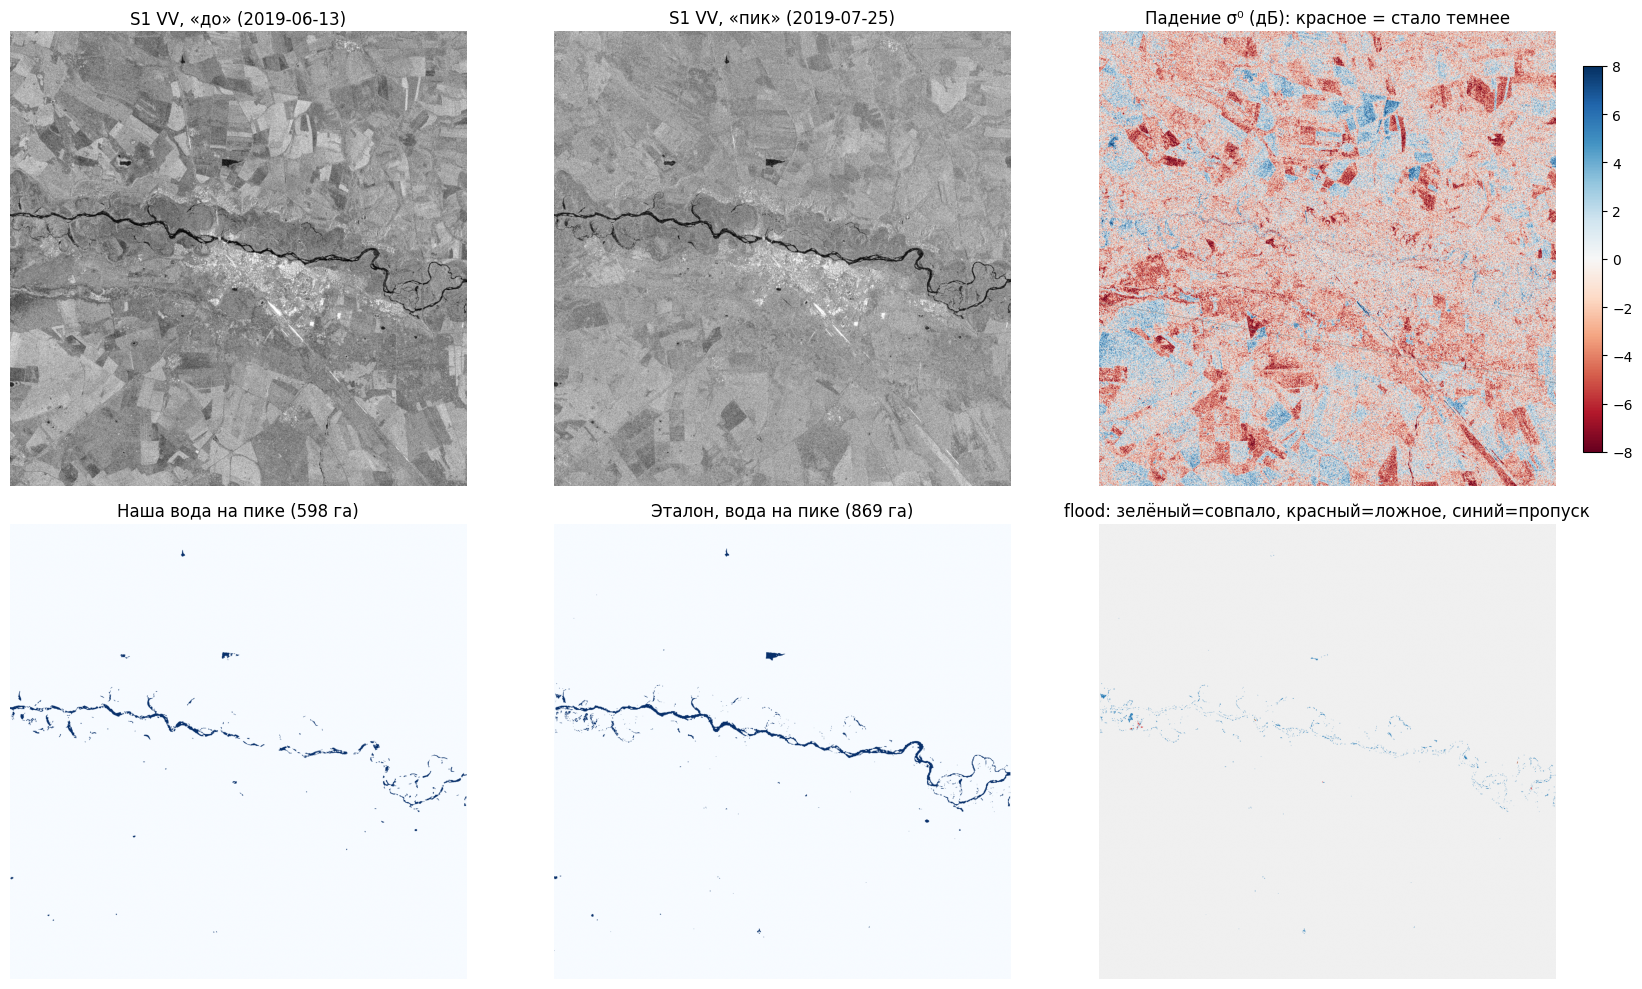

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio

with rasterio.open(sample_avail.reference_mask_path) as ds:
    ref = ds.read()  # каналы: flood, water_pre, water_peak, permanent, receded
ref_flood, ref_peak = ref[0].astype(bool), ref[2].astype(bool)

# Крупные растры показываем прореженными, иначе matplotlib съест всю память
step = max(1, masks.grid.width // 1200)
sl = (slice(None, None, step), slice(None, None, step))

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes[0, 0].imshow(pre.vv_db[sl], cmap="gray", vmin=-25, vmax=0)
axes[0, 0].set_title(f"S1 VV, «до» ({sample_row['date_pre_sar']})")
axes[0, 1].imshow(peak.vv_db[sl], cmap="gray", vmin=-25, vmax=0)
axes[0, 1].set_title(f"S1 VV, «пик» ({sample_row['date_peak_sar']})")

drop = (pre.vv_db - peak.vv_db)[sl]
im = axes[0, 2].imshow(drop, cmap="RdBu", vmin=-8, vmax=8)
axes[0, 2].set_title("Падение σ⁰ (дБ): красное = стало темнее")
plt.colorbar(im, ax=axes[0, 2], fraction=0.035)

axes[1, 0].imshow(masks.water_peak[sl], cmap="Blues")
axes[1, 0].set_title(f"Наша вода на пике ({mask_area_ha(masks.water_peak, masks.grid):.0f} га)")
axes[1, 1].imshow(ref_peak[sl], cmap="Blues")
axes[1, 1].set_title(f"Эталон, вода на пике ({ref_peak.sum() * masks.grid.pixel_area_ha:.0f} га)")

agreement = np.zeros(masks.flood[sl].shape, dtype=np.int8)
agreement[masks.flood[sl] & ref_flood[sl]] = 1      # совпало
agreement[masks.flood[sl] & ~ref_flood[sl]] = 2     # ложное срабатывание
agreement[~masks.flood[sl] & ref_flood[sl]] = 3     # пропуск
axes[1, 2].imshow(agreement, cmap=plt.matplotlib.colors.ListedColormap(
    ["#f0f0f0", "#2ca02c", "#d62728", "#1f77b4"]), vmin=0, vmax=3)
axes[1, 2].set_title("flood: зелёный=совпало, красный=ложное, синий=пропуск")

for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. Полный прогон по всем парам

Прогресс-бар идёт по парам, вложенный — по окнам выгрузки. После каждой пары результат
пишется в `CHECKPOINT_DIR` на Drive, поэтому обрыв сессии не теряет работу: перезапустите
ячейку, и посчитанные пары подхватятся (`RESUME = True` в разделе 3).


In [31]:
import time
import numpy as np

PREDICTIONS_DIR = os.path.join(OUT_DIR, "predictions")
REPORTS_DIR = os.path.join(OUT_DIR, "reports")
VECTORS_DIR = os.path.join(OUT_DIR, "vectors")
for d in (PREDICTIONS_DIR, REPORTS_DIR, VECTORS_DIR):
    os.makedirs(d, exist_ok=True)

results, reports, timings = [], [], []
run_started = time.time()

# Отпечаток конфигурации: маски, посчитанные ДРУГОЙ конфигурацией, к
# переиспользованию непригодны. Без этой проверки повторный прогон после
# правки алгоритма молча воспроизводит старые числа — ровно это и
# произошло один раз, дав побайтово тот же Score.
FINGERPRINT = config_fingerprint(CFG.to_dict(), PIPELINE_VERSION)
_stale = stale_pairs(CHECKPOINT_DIR, list(pairs["pair_id"]), FINGERPRINT)
print(f"Отпечаток конфигурации: {FINGERPRINT} (pipeline {PIPELINE_VERSION})")
if _stale:
    print(f"Чекпоинты от другой конфигурации ({len(_stale)} пар) будут ПЕРЕСЧИТАНЫ.")
    print("Скачанные снимки при этом переиспользуются — сеть не трогаем.")
else:
    print("Несовместимых чекпоинтов нет.")
print()

def _unpack_arrays(raw):
    opt = {k[4:]: v for k, v in raw.items() if k.startswith("opt_")}
    if "valid" in opt:
        opt["valid"] = opt["valid"] > 0.5
    return DateArrays(vv_db=raw["vv_db"], optical=opt or None)

def _pack_arrays(arrays):
    payload = {"vv_db": arrays.vv_db}
    if arrays.optical:
        payload.update({f"opt_{k}": v.astype(np.float32)
                        for k, v in arrays.optical.items() if v is not None})
    return payload

pair_bar = tqdm(list(pairs.iterrows()), desc="Пары", unit="pair")
for _, row in pair_bar:
    pair_id = row["pair_id"]
    pair_bar.set_postfix_str(pair_id[:34])
    avail = availabilities[pair_id]

    if not avail.ready_for_inference:
        print(f"[{pair_id}] ПРОПУСК — нет файлов, пишем 0 га")
        results.append(PairResult(pair_id, 0.0, 0.0, 0.0))
        continue

    if RESUME and ckpt.is_complete(CHECKPOINT_DIR, pair_id, FINGERPRINT):
        _, summary = ckpt.load_pair(CHECKPOINT_DIR, pair_id)
        results.append(PairResult(pair_id, summary["flood_ha"],
                                  summary["water_pre_ha"], summary["water_peak_ha"]))
        reports.append(summary["report"])
        print(f"[{pair_id}] из чекпоинта (та же конфигурация): flood={summary['flood_ha']:.1f} га")
        continue

    grid = read_grid(avail.reference_mask_path)

    # --- Снимки: дорогие (сеть), от алгоритма не зависят -> кэш навсегда ---
    t0 = time.time()
    cached_pre = ckpt.load_arrays(CHECKPOINT_DIR, pair_id, "pre") if CACHE_ARRAYS else None
    cached_peak = ckpt.load_arrays(CHECKPOINT_DIR, pair_id, "peak") if CACHE_ARRAYS else None

    if cached_pre is not None and cached_peak is not None:
        p_pre, p_peak = _unpack_arrays(cached_pre), _unpack_arrays(cached_peak)
        print(f"[{pair_id}] снимки из кэша (без обращения к GEE)")
    else:
        p_pre = fetch_pair_arrays(avail.rasters_dir, grid, "pre", CFG,
                                  progress=make_tile_progress(f"{pair_id[:18]} pre"))
        p_peak = fetch_pair_arrays(avail.rasters_dir, grid, "peak", CFG,
                                   progress=make_tile_progress(f"{pair_id[:18]} peak"))
        if CACHE_ARRAYS:
            ckpt.save_arrays(CHECKPOINT_DIR, pair_id, "pre", _pack_arrays(p_pre))
            ckpt.save_arrays(CHECKPOINT_DIR, pair_id, "peak", _pack_arrays(p_peak))
    t_fetch = time.time() - t0

    # --- Маски: дёшево, полностью определяются конфигурацией ---
    t0 = time.time()
    m = segment_pair(pair_id, avail.reference_mask_path, avail.aux_terrain_path,
                     hydrography, p_pre, p_peak, CFG)
    t_segment = time.time() - t0

    flood_ha = mask_area_ha(m.flood, m.grid)
    water_pre_ha = mask_area_ha(m.water_pre, m.grid)
    water_peak_ha = mask_area_ha(m.water_peak, m.grid)
    aoi_ha_pair = row["aoi_km2"] * 100

    problems = validate_pair_result(flood_ha, water_pre_ha, water_peak_ha, aoi_ha_pair)
    if problems:
        print(f"[{pair_id}] ВНИМАНИЕ: {problems}")

    report = build_pair_report(pair_id, m.grid, m.water_pre, m.water_peak, m.flood,
                               m.receded, m.terrain, aoi_ha_pair,
                               meta={"thresholds": m.diagnostics,
                                     "fingerprint": FINGERPRINT,
                                     "timing_s": {"fetch": round(t_fetch, 1),
                                                  "segment": round(t_segment, 1)}})
    reports.append(report)
    timings.append({"pair_id": pair_id, "fetch_s": t_fetch, "segment_s": t_segment,
                    "megapixels": m.grid.width * m.grid.height / 1e6})

    write_flood_mask_tif(m.flood, m.grid, os.path.join(PREDICTIONS_DIR, f"{pair_id}_flood.tif"))
    write_report(report, os.path.join(REPORTS_DIR, f"{pair_id}.json"))
    write_geojson({"water_pre": m.water_pre, "water_peak": m.water_peak,
                   "flood": m.flood, "receded": m.receded},
                  m.grid, os.path.join(VECTORS_DIR, f"{pair_id}.geojson"),
                  min_pixels=CFG.postprocess.min_mapping_unit_px)
    ckpt.save_pair(CHECKPOINT_DIR, pair_id,
                   {"flood": m.flood, "water_pre": m.water_pre,
                    "water_peak": m.water_peak, "receded": m.receded},
                   m.grid,
                   {"flood_ha": flood_ha, "water_pre_ha": water_pre_ha,
                    "water_peak_ha": water_peak_ha, "report": report},
                   fingerprint=FINGERPRINT)

    results.append(PairResult(pair_id, flood_ha, water_pre_ha, water_peak_ha))
    d = m.diagnostics["peak"]
    _fb = (", откат: " + d["fallback"]) if d.get("fallback") else ""
    print(f"[{pair_id}] flood={flood_ha:8.1f} га | water_pre={water_pre_ha:8.1f} | "
          f"water_peak={water_peak_ha:8.1f} | порог {d.get('threshold_db')} дБ "
          f"(тайлов {d.get('tiles_kept')}/{d.get('tiles_scored')}{_fb}) | "
          f"{t_fetch:.0f}s+{t_segment:.0f}s")

SUBMISSION_PATH = os.path.join(OUT_DIR, "submission.csv")
write_submission_csv(results, SUBMISSION_PATH)
if reports:
    pd.DataFrame(reports_to_csv_rows(reports)).to_csv(
        os.path.join(REPORTS_DIR, "summary.csv"), index=False)

total_min = (time.time() - run_started) / 60
print(f"\n{SUBMISSION_PATH} — {len(results)} пар, {total_min:.1f} мин")
if timings:
    tdf = pd.DataFrame(timings)
    print(f"Выгрузка: {tdf.fetch_s.sum()/60:.1f} мин | сегментация: {tdf.segment_s.sum()/60:.1f} мин")
    display(tdf.round(1))


Отпечаток конфигурации: 2744de0211b3571a (pipeline 2026.02-split-consensus)
Чекпоинты от другой конфигурации (11 пар) будут ПЕРЕСЧИТАНЫ.
Скачанные снимки при этом переиспользуются — сеть не трогаем.



Пары:   0%|          | 0/11 [00:00<?, ?pair/s]

baseline_2018_09_l pre [VV]:   0%|          | 0/9 [00:00<?, ?tile/s]

baseline_2018_09_l peak [VV]:   0%|          | 0/9 [00:00<?, ?tile/s]

[baseline_2018_09_low__blagoveshchensk] flood=    45.1 га | water_pre= 11053.5 | water_peak=  8659.5 | порог -16.466 дБ (тайлов 10/72) | 26s+20s


...

flood_2021_08_zeya pre [NDWI,MNDWI,NDVI,valid,AWEISH]:   0%|          | 0/25 [00:00<?, ?tile/s]

flood_2021_08_zeya peak [VV]:   0%|          | 0/9 [00:00<?, ?tile/s]

flood_2021_08_zeya peak [NDWI,MNDWI,NDVI,valid,AWEISH]:   0%|          | 0/25 [00:00<?, ?tile/s]

[flood_2021_08_zeya__svobodny] flood=   408.1 га | water_pre=  3915.1 | water_peak=  2184.7 | порог -16.854 дБ (тайлов 22/64) | 105s+16s

/content/drive/MyDrive/cosmohack2/hydrowatch_run/outputs/submission.csv — 11 пар, 17.0 мин
Выгрузка: 12.3 мин | сегментация: 2.8 мин


,pair_id,fetch_s,segment_s,megapixels
0,baseline_2018_09_low__blagoveshchensk,26.5,19.7,16.5
1,baseline_2018_09_low__konstantinovka,21.4,14.7,12.4
2,baseline_2018_09_low__svobodny,24.5,15.9,13.3
3,flood_2019_07_amur__belogorsk,73.6,11.2,9.1
4,flood_2019_07_amur__blagoveshchensk,29.4,20.0,16.5
5,flood_2019_07_amur__konstantinovka,21.3,14.8,12.4
6,flood_2019_07_amur__svobodny,104.4,16.2,13.3
7,flood_2021_06_amur__blagoveshchensk,150.2,19.8,16.5
8,flood_2021_06_amur__konstantinovka,103.1,14.8,12.4
9,flood_2021_06_amur__poyarkovo,81.0,4.2,10.9


## 11. Самопроверка по метрике организаторов

Формула из постановки, посчитанная локально на выданных эталонах. Это **не** участвует в
формировании ответа — только самопроверка перед сдачей.


In [32]:
import glob, json

def load_reference(data_dir, pairs_df):
    rows, kind, aoi_ha, aoi_of_pair = [], {}, {}, {}
    idx = pairs_df.set_index("pair_id")
    for p in sorted(glob.glob(os.path.join(data_dir, "**", "reference_*.json"), recursive=True)):
        with open(p, "r", encoding="utf-8") as fh:
            meta = json.load(fh)
        pid = meta["pair_id"]
        if pid not in idx.index:
            continue
        s = meta["stats"]
        rows.append({"pair_id": pid, "flood_ha": s["flood_ha"],
                     "water_pre_ha": s["water_pre_ha"], "water_peak_ha": s["water_peak_ha"]})
        kind[pid] = idx.loc[pid, "event_kind"]
        aoi_ha[pid] = idx.loc[pid, "aoi_km2"] * 100.0
        aoi_of_pair[pid] = idx.loc[pid, "aoi_id"]
    return pd.DataFrame(rows), kind, aoi_ha, aoi_of_pair

reference, kind, aoi_ha, aoi_of_pair = load_reference(DATA_DIR, pairs)
submission = pd.read_csv(SUBMISSION_PATH)
rep = score_submission(submission, reference, kind, aoi_ha)

print(f"Score        = {rep.score:.4f}")
print(f"  Q_flood      (вес 0.45) = {rep.q_flood:.4f}")
print(f"  Q_water_peak (вес 0.25) = {rep.q_water_peak:.4f}")
print(f"  Q_water_pre  (вес 0.15) = {rep.q_water_pre:.4f}")
print(f"  Spec_base    (вес 0.15) = {rep.spec_base:.4f}")

pp = rep.per_pair.copy()
pp["flood_err_ha"] = (pp["flood_pred"] - pp["flood_ref"])
display(pp[["pair_id", "kind", "flood_pred", "flood_ref", "flood_err_ha",
            "water_peak_pred", "water_peak_ref"]].round(1))


Score        = 0.3837
  Q_flood      (вес 0.45) = 0.2149
  Q_water_peak (вес 0.25) = 0.3917
  Q_water_pre  (вес 0.15) = 0.2944
  Spec_base    (вес 0.15) = 0.9663


,pair_id,kind,flood_pred,flood_ref,flood_err_ha,water_peak_pred,water_peak_ref
0,flood_2019_07_amur__belogorsk,rain_flood,5.8,187.2,-181.4,597.6,869.3
1,flood_2019_07_amur__blagoveshchensk,rain_flood,166.6,386.3,-219.7,9392.6,8894.4
2,flood_2019_07_amur__konstantinovka,rain_flood,155.9,643.5,-487.6,7949.5,7267.0
3,flood_2019_07_amur__svobodny,rain_flood,29.2,213.3,-184.0,3374.9,991.4
4,flood_2021_06_amur__blagoveshchensk,rain_flood,1156.2,882.6,273.6,7965.6,2845.2
5,flood_2021_06_amur__konstantinovka,rain_flood,0.0,107.3,-107.3,0.0,172.9
6,flood_2021_06_amur__poyarkovo,rain_flood,0.0,2167.3,-2167.3,0.0,8910.0
7,flood_2021_08_zeya__svobodny,rain_flood,408.1,2179.0,-1770.8,2184.7,4740.9
8,baseline_2018_09_low__blagoveshchensk,baseline,45.1,197.0,-151.9,8659.5,8469.3
9,baseline_2018_09_low__konstantinovka,baseline,85.7,25.0,60.7,8687.3,1730.9


### 11.1 Кросс-валидация по районам (leave-one-AOI-out)

11 пар приходятся всего на 5 районов, поэтому разбиение по парам протекает: порог,
подобранный на Благовещенске-2019 и проверенный на Благовещенске-2021, не валидирован, а
запомнен. Корректная схема — держать в валидации **целый район**. Разброс Score между
фолдами показывает, насколько решение переносится на новую территорию.


In [33]:
fold_rows = []
for held_out in sorted(set(aoi_of_pair.values())):
    fold_pairs = [p for p, a in aoi_of_pair.items() if a == held_out]
    sub_f = submission[submission["pair_id"].isin(fold_pairs)]
    ref_f = reference[reference["pair_id"].isin(fold_pairs)]
    if sub_f.empty or ref_f.empty:
        continue
    r = score_submission(sub_f, ref_f, kind, aoi_ha)
    fold_rows.append({"Район (held out)": held_out, "пар": len(ref_f),
                      "Score": r.score, "Q_flood": r.q_flood,
                      "Q_water_peak": r.q_water_peak, "Spec_base": r.spec_base})
folds = pd.DataFrame(fold_rows).round(4)
display(folds)
print(f"Score по фолдам: среднее {folds['Score'].mean():.4f}, разброс "
      f"{folds['Score'].min():.4f}–{folds['Score'].max():.4f}")


,Район (held out),пар,Score,Q_flood,Q_water_peak,Spec_base
0,belogorsk,1,NaN,0.0309,0.6874,NaN
1,blagoveshchensk,3,0.5203,0.5606,0.4720,1.000
2,konstantinovka,3,0.3822,0.1211,0.5207,0.899
3,poyarkovo,1,NaN,0.0000,0.0000,NaN
4,svobodny,3,0.3545,0.1622,0.2304,1.000


Score по фолдам: среднее 0.4190, разброс 0.3545–0.5203


## 12. Калибровка и абляции

Снимки уже лежат в кэше на Drive, поэтому пересегментировать их десятками конфигураций
почти бесплатно. Здесь решается сразу две задачи критерия «Экспериментальная проверка»:

1. **Абляции** — измеренный вклад каждого механизма, а не заявленный.
2. **Честный подбор конфигурации.** Постановка прямо разрешает использовать эталон «для
   обучения, подбора порогов и самопроверки» — но подбирать нужно правильно. 11 пар
   приходятся на 5 районов, поэтому фолдом берётся **целый район**: конфигурация
   выбирается на остальных районах и только потом применяется к отложенному. Разрыв
   между «лучшим в выборке» и «на отложенном районе» и есть честная оценка того, сколько
   из прироста реально, а не подогнано.


In [34]:
def load_cached_inputs(pair_ids):
    """Поднимает скачанные снимки из кэша на Drive (сеть не трогается)."""
    items = []
    for pid in pair_ids:
        a = availabilities[pid]
        pre_raw = ckpt.load_arrays(CHECKPOINT_DIR, pid, "pre")
        peak_raw = ckpt.load_arrays(CHECKPOINT_DIR, pid, "peak")
        if pre_raw is None or peak_raw is None:
            continue
        def unpack(raw):
            opt = {k[4:]: v for k, v in raw.items() if k.startswith("opt_")}
            if "valid" in opt:
                opt["valid"] = opt["valid"] > 0.5
            return DateArrays(vv_db=raw["vv_db"], optical=opt or None)
        items.append(PairInputs(pid, a.reference_mask_path, a.aux_terrain_path,
                                unpack(pre_raw), unpack(peak_raw)))
    return items

CAL_INPUTS = load_cached_inputs([p for p in pairs["pair_id"] if p in ready_pair_ids])
print(f"Пар поднято из кэша: {len(CAL_INPUTS)}")
if not CAL_INPUTS:
    print("Кэш пуст — включите CACHE_ARRAYS в разделе 3 и перезапустите раздел 10.")


Пар поднято из кэша: 11


In [35]:
VARIANTS = {
    # --- абляции: что даёт каждый механизм ---
    "A0 v0 baseline (Otsu в диапазоне + OR)": CFG.replace(
        sar={"threshold_method": "global_in_range"}, fusion={"method": "or"},
        optical={"adaptive_threshold": False, "use_aweish": False},
        change={"require_backscatter_drop": False}),
    "A1 + тайловый порог (BC+AshD)": CFG.replace(
        fusion={"method": "or"},
        optical={"adaptive_threshold": False, "use_aweish": False},
        change={"require_backscatter_drop": False}),
    "A2 + падение σ⁰ ≥ 3 дБ": CFG.replace(
        fusion={"method": "or"},
        optical={"adaptive_threshold": False, "use_aweish": False}),
    "A3 + AWEIsh и адаптивный MNDWI": CFG.replace(fusion={"method": "or"}),

    # --- выбор схемы слияния (ключевой вопрос кейса) ---
    "B1 слияние: консенсус SAR∧оптика": CFG.replace(fusion={"method": "consensus"}),
    "B2 слияние: строгий консенсус (облако = не подтверждено)": CFG.replace(
        fusion={"method": "strict_consensus"}),
    "B2b слияние: Демпстер-Шейфер": CFG.replace(fusion={"method": "ds"}),
    "B3 только SAR (оптика выключена)": CFG.replace(
        fusion={"method": "consensus"}, optical={"use_aweish": False, "adaptive_threshold": False}),

    # --- гидрологические пороги ---
    "C1 HAND ≤ 15 м": CFG.replace(fusion={"method": "consensus"}, postprocess={"hand_max_m": 15.0}),
    "C2 HAND ≤ 10 м": CFG.replace(fusion={"method": "consensus"}, postprocess={"hand_max_m": 10.0}),
    "C3 без фильтра связности": CFG.replace(
        fusion={"method": "consensus"}, postprocess={"connectivity_filter": False}),
    "C4 порог σ⁰ шире: [-24,-10] дБ": CFG.replace(
        fusion={"method": "consensus"}, sar={"valid_range_db": (-24.0, -10.0)}),
}

def variant_progress(done, total, name):
    print(f"  [{done}/{total}] {name}")

if CAL_INPUTS:
    in_sample, out_of_fold, best_name = sweep(
        VARIANTS, CAL_INPUTS, hydrography, reference, kind, aoi_ha, aoi_of_pair,
        progress=variant_progress)

    print()
    print("=== В выборке (все пары; так выглядел бы наивный подбор) ===")
    display(in_sample.round(4))
    print("=== Честно: конфигурация выбрана без отложенного района ===")
    display(out_of_fold)
    print()
    print(f"Честный выбор: {best_name}")
    if not out_of_fold.empty:
        print(f"Score на отложенных районах: {out_of_fold['heldout_Score'].mean():.4f} "
              f"(в выборке лучший: {in_sample.iloc[0]['Score']:.4f})")
        print("Разрыв между этими числами — та часть прироста, которая является подгонкой.")


  [1/12] A0 v0 baseline (Otsu в диапазоне + OR)
  [2/12] A1 + тайловый порог (BC+AshD)
  [3/12] A2 + падение σ⁰ ≥ 3 дБ
  [4/12] A3 + AWEIsh и адаптивный MNDWI
  [5/12] B1 слияние: консенсус SAR∧оптика
  [6/12] B2 слияние: строгий консенсус (облако = не подтверждено)
  [7/12] B2b слияние: Демпстер-Шейфер
  [8/12] B3 только SAR (оптика выключена)
  [9/12] C1 HAND ≤ 15 м
  [10/12] C2 HAND ≤ 10 м
  [11/12] C3 без фильтра связности
  [12/12] C4 порог σ⁰ шире: [-24,-10] дБ

=== В выборке (все пары; так выглядел бы наивный подбор) ===


,variant,Score,Q_flood,Q_water_peak,Q_water_pre,Spec_base
0,C3 без фильтра связности,0.4045,0.3636,0.3918,0.2946,0.6583
1,B2b слияние: Демпстер-Шейфер,0.4044,0.2564,0.4024,0.2895,0.9663
2,B2 слияние: строгий консенсус (облако = не под...,0.3854,0.1974,0.3433,0.4384,0.9663
3,C2 HAND ≤ 10 м,0.3838,0.2149,0.3918,0.2946,0.9663
4,C1 HAND ≤ 15 м,0.3838,0.2149,0.3918,0.2946,0.9663
5,B1 слияние: консенсус SAR∧оптика,0.3838,0.2149,0.3918,0.2946,0.9663
6,B3 только SAR (оптика выключена),0.3838,0.2149,0.3918,0.2946,0.9663
7,"C4 порог σ⁰ шире: [-24,-10] дБ",0.3838,0.2149,0.3918,0.2946,0.9663
8,A2 + падение σ⁰ ≥ 3 дБ,0.3673,0.2280,0.3479,0.2186,0.9663
9,A3 + AWEIsh и адаптивный MNDWI,0.3673,0.2280,0.3479,0.2186,0.9663


=== Честно: конфигурация выбрана без отложенного района ===


,held_out_aoi,pairs,chosen_on_train,train_Score,heldout_Score,heldout_Q_flood,heldout_Q_water_peak
0,belogorsk,1,B2 слияние: строгий консенсус (облако = не под...,0.4140,NaN,0.0000,0.1443
1,blagoveshchensk,3,B2b слияние: Демпстер-Шейфер,0.4166,0.3651,0.2158,0.4721
2,konstantinovka,3,C3 без фильтра связности,0.4270,0.3864,0.4299,0.5208
3,poyarkovo,1,C3 без фильтра связности,0.4482,NaN,0.0000,0.0000
4,svobodny,3,C2 HAND ≤ 10 м,0.3926,0.3550,0.1630,0.2308



Честный выбор: C3 без фильтра связности
Score на отложенных районах: 0.3688 (в выборке лучший: 0.4045)
Разрыв между этими числами — та часть прироста, которая является подгонкой.


### 12.1 Применить выбранную конфигурацию

Если калибровка выбрала не ту конфигурацию, что стоит в `configs/default.yaml`, ячейка
ниже пересчитает `submission.csv` победившей — снова без обращения к сети, из кэша.


In [36]:
APPLY_BEST = True

if CAL_INPUTS and APPLY_BEST:
    best_cfg = VARIANTS[best_name]
    best_preds = run_variant(best_cfg, CAL_INPUTS, hydrography)

    merged = {r.pair_id: r for r in results}
    for _, row in best_preds.iterrows():
        merged[row["pair_id"]] = PairResult(row["pair_id"], row["flood_ha"],
                                            row["water_pre_ha"], row["water_peak_ha"])
    results = [merged[p] for p in pairs["pair_id"] if p in merged]
    write_submission_csv(results, SUBMISSION_PATH)

    final = score_submission(pd.read_csv(SUBMISSION_PATH), reference, kind, aoi_ha)
    print(f"submission.csv пересчитан конфигурацией: {best_name}")
    print(f"Score = {final.score:.4f}  (Q_flood {final.q_flood:.4f}, "
          f"Q_water_peak {final.q_water_peak:.4f}, Q_water_pre {final.q_water_pre:.4f}, "
          f"Spec_base {final.spec_base:.4f})")

    import yaml
    with open(os.path.join(OUT_DIR, "chosen_config.yaml"), "w", encoding="utf-8") as fh:
        yaml.safe_dump(best_cfg.to_dict(), fh, allow_unicode=True)
    print("Конфигурация сохранена:", os.path.join(OUT_DIR, "chosen_config.yaml"))


submission.csv пересчитан конфигурацией: C3 без фильтра связности
Score = 0.4045  (Q_flood 0.3636, Q_water_peak 0.3918, Q_water_pre 0.2946, Spec_base 0.6583)
Конфигурация сохранена: /content/drive/MyDrive/cosmohack2/hydrowatch_run/outputs/chosen_config.yaml


## 13. Интерактивная карта динамики затопления

Слои: вода на дату «до», вода на пике и зона нового затопления поверх картографической
подложки, с переключением и всплывающими подсказками по площади каждого контура.
Контуры — те же GeoJSON, что уходят в выгрузку (EPSG:4326, атрибуты id/type/area).


In [37]:
import folium
import json

MAP_PAIR = sample_row["pair_id"]  # поменяйте на любой pair_id
geojson_path = os.path.join(VECTORS_DIR, f"{MAP_PAIR}.geojson")
if not os.path.exists(geojson_path):
    _, _summary = ckpt.load_pair(CHECKPOINT_DIR, MAP_PAIR)
    print("Контуры ещё не выгружены для этой пары — запустите раздел 10")
else:
    with open(geojson_path, "r", encoding="utf-8") as fh:
        fc = json.load(fh)

    aoi_row = pairs.set_index("pair_id").loc[MAP_PAIR]
    aoi_geo = json.load(open(resolve(DATA_DIR, "vectors/aoi.geojson"), encoding="utf-8"))
    aoi_feat = [f for f in aoi_geo["features"] if f["properties"]["aoi_id"] == aoi_row["aoi_id"]][0]
    lon = aoi_feat["properties"]["lon"]; lat = aoi_feat["properties"]["lat"]

    m_map = folium.Map(location=[lat, lon], zoom_start=10, tiles="OpenStreetMap")
    folium.TileLayer("CartoDB positron", name="Светлая подложка").add_to(m_map)

    STYLES = {
        "water_pre":  {"color": "#3186cc", "label": "Вода «до»"},
        "water_peak": {"color": "#08306b", "label": "Вода на пике"},
        "flood":      {"color": "#d62728", "label": "Новое затопление"},
        "receded":    {"color": "#ff7f0e", "label": "Ушедшая вода"},
    }
    for layer, style in STYLES.items():
        feats = [f for f in fc["features"] if f["properties"]["type"] == layer]
        if not feats:
            continue
        total_ha = sum(f["properties"]["area_ha"] for f in feats)
        folium.GeoJson(
            {"type": "FeatureCollection", "features": feats},
            name=f"{style['label']} — {total_ha:.0f} га ({len(feats)} контуров)",
            style_function=lambda _f, c=style["color"]: {
                "color": c, "weight": 1, "fillColor": c, "fillOpacity": 0.45},
            tooltip=folium.GeoJsonTooltip(fields=["id", "type", "area_ha"],
                                          aliases=["Контур", "Тип", "Площадь, га"]),
            show=(layer in ("flood", "water_peak")),
        ).add_to(m_map)

    folium.GeoJson(aoi_feat, name="Граница района",
                   style_function=lambda _f: {"color": "#333", "weight": 2,
                                              "fill": False, "dashArray": "5,5"}).add_to(m_map)
    folium.LayerControl(collapsed=False).add_to(m_map)

    map_path = os.path.join(OUT_DIR, f"map_{MAP_PAIR}.html")
    m_map.save(map_path)
    print("Карта сохранена:", map_path)
    display(m_map)


Карта сохранена: /content/drive/MyDrive/cosmohack2/hydrowatch_run/outputs/map_flood_2019_07_amur__belogorsk.html


## 14. Сводный отчёт

Площади на обе даты, прирост и убыль в га и км², доля от площади района и распределение
затопления по типам земного покрова — в машиночитаемом виде (`reports/*.json` +
`reports/summary.csv`).


In [38]:
if reports:
    r = [x for x in reports if x["pair_id"] == sample_row["pair_id"]]
    r = r[0] if r else reports[0]
    print(f"=== {r['pair_id']} ===")
    print(f"Район: {r['aoi']['km2']} км²")
    print(f"Вода «до»:  {r['water_surface']['pre']['ha']:>10.1f} га  ({r['water_surface']['pre']['km2']} км²)")
    print(f"Вода пик:   {r['water_surface']['peak']['ha']:>10.1f} га  ({r['water_surface']['peak']['km2']} км²)")
    print(f"Прирост:    {r['change']['flood_new_water']['ha']:>10.1f} га  (новое затопление)")
    print(f"Убыль:      {r['change']['receded']['ha']:>10.1f} га")
    print(f"Чистый рост:{r['change']['net_gain']['ha']:>10.1f} га")
    print(f"Доля затопления от района: {100 * r['shares']['flood_of_aoi']:.3f} %")
    print("\nРаспределение затопления по типам покрова:")
    for key, v in r["flood_landcover_breakdown"].items():
        print(f"  {v['label']:<52} {v['area_ha']:>9.1f} га ({100*v['share_of_flood']:5.1f} %)")

    summary_csv = os.path.join(REPORTS_DIR, "summary.csv")
    if os.path.exists(summary_csv):
        print("\n=== Сводка по всем парам ===")
        display(pd.read_csv(summary_csv).round(2))


=== flood_2019_07_amur__belogorsk ===
Район: 913.851 км²
Вода «до»:       371.3 га  (3.7132 км²)
Вода пик:        597.6 га  (5.9756 км²)
Прирост:           5.8 га  (новое затопление)
Убыль:            35.4 га
Чистый рост:     226.2 га
Доля затопления от района: 0.006 %

Распределение затопления по типам покрова:
  Застроенные территории (ESA WorldCover)                    0.0 га (  0.0 %)
  Постоянная вода (JRC GSW occurrence >= 80%)                0.0 га (  0.0 %)
  Сезонная вода (JRC GSW max_extent, не постоянная)          4.8 га ( 82.2 %)
  Прочие типы покрова                                        1.0 га ( 17.8 %)

=== Сводка по всем парам ===


,pair_id,aoi_km2,water_pre_ha,water_peak_ha,flood_ha,receded_ha,net_gain_ha,flood_share_of_aoi,flood_on_builtup_ha
0,baseline_2018_09_low__blagoveshchensk,1585.93,11053.47,8659.53,45.10,1377.23,-2393.94,0.00,0.0
1,baseline_2018_09_low__konstantinovka,1201.22,11822.20,8687.32,85.67,3559.16,-3134.88,0.00,0.0
2,baseline_2018_09_low__svobodny,1297.90,5544.39,4691.44,12.36,380.50,-852.95,0.00,0.0
3,flood_2019_07_amur__belogorsk,913.85,371.32,597.56,5.79,35.44,226.24,0.00,0.0
4,flood_2019_07_amur__blagoveshchensk,1649.17,9357.90,9392.63,166.62,382.30,34.73,0.00,0.0
5,flood_2019_07_amur__konstantinovka,1235.45,7892.33,7949.54,155.90,522.91,57.21,0.00,0.0
6,flood_2019_07_amur__svobodny,1328.96,3122.22,3374.94,29.23,182.45,252.72,0.00,0.0
7,flood_2021_06_amur__blagoveshchensk,1585.93,5496.99,7965.62,1156.24,535.71,2468.63,0.01,0.0
8,flood_2021_06_amur__konstantinovka,1235.45,8667.42,0.00,0.00,2775.68,-8667.42,0.00,0.0
9,flood_2021_06_amur__poyarkovo,1090.71,0.00,0.00,0.00,0.00,0.00,0.00,0.0


## 15. Что сдавать

- `outputs/submission.csv` — файл посылки (4 колонки, одна строка на пару);
- `outputs/predictions/<pair_id>_flood.tif` — маски, uint8, сетка пары;
- `outputs/vectors/*.geojson`, `outputs/reports/*.json`, `outputs/map_*.html` — материалы
  сервиса и отчёта.

Всё это лежит в `WORK_DIR` на Google Drive, то есть переживает перезапуск Colab.


In [39]:
import shutil

archive_base = os.path.join(WORK_DIR, "hydrowatch_submission")
shutil.make_archive(archive_base, "zip", OUT_DIR)
print("Архив:", archive_base + ".zip")

print("\nСостав outputs:")
for root, dirs, files in os.walk(OUT_DIR):
    depth = root[len(OUT_DIR):].count(os.sep)
    if depth <= 1:
        print(f"  {root[len(OUT_DIR):] or '/'}: {len(files)} файл(ов)")

sub = pd.read_csv(SUBMISSION_PATH)
assert sub["pair_id"].nunique() == len(pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))), \
    "перечень пар не совпадает с sample_submission.csv"
assert not sub.isna().any().any(), "в submission.csv есть пропуски"
assert (sub["flood_ha"] <= sub["water_peak_ha"] + 1e-6).all(), "flood_ha > water_peak_ha"
assert (sub[["flood_ha", "water_pre_ha", "water_peak_ha"]] >= 0).all().all(), "отрицательные площади"
print("\nФормальные проверки сабмита пройдены.")
display(sub)


Архив: /content/drive/MyDrive/cosmohack2/hydrowatch_run/hydrowatch_submission.zip

Состав outputs:
  /: 3 файл(ов)
  /predictions: 11 файл(ов)
  /reports: 12 файл(ов)
  /vectors: 11 файл(ов)

Формальные проверки сабмита пройдены.


,pair_id,flood_ha,water_pre_ha,water_peak_ha
0,baseline_2018_09_low__blagoveshchensk,93.46,11053.15,8664.60
1,baseline_2018_09_low__konstantinovka,974.58,11827.18,8674.31
2,baseline_2018_09_low__svobodny,60.50,5543.11,4691.36
3,flood_2019_07_amur__belogorsk,28.93,371.18,597.34
4,flood_2019_07_amur__blagoveshchensk,465.03,9351.13,9391.21
5,flood_2019_07_amur__konstantinovka,553.36,7884.40,7948.22
6,flood_2019_07_amur__svobodny,272.01,3123.49,3375.59
7,flood_2021_06_amur__blagoveshchensk,2285.90,5500.92,7966.96
8,flood_2021_06_amur__konstantinovka,0.00,8667.82,0.00
9,flood_2021_06_amur__poyarkovo,0.00,0.00,0.00
